# Signal Quality Analysis
Load saved waveform artifacts and compute Pearson, DTW, SNR, and PSD correlation.

In [1]:
from pathlib import Path
from fastdtw import fastdtw
import math
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
try:
    from scipy.signal import welch
except Exception:
    welch = None

In [2]:
def to_1d_numpy(x):
    return x.detach().cpu().numpy().astype(np.float64).reshape(-1)

def reconstruct_subject_signal(subject_chunks):
    keys = sorted(subject_chunks.keys())
    chunks = [to_1d_numpy(subject_chunks[k]) for k in keys]
    return np.concatenate(chunks) if chunks else np.array([], dtype=np.float64)

def pearson_corr(x, y):
    n = min(len(x), len(y))
    if n == 0:
        return np.nan
    x = x[:n]
    y = y[:n]
    if np.std(x) < 1e-12 or np.std(y) < 1e-12:
        return np.nan
    return float(np.corrcoef(x, y)[0, 1])

def dtw_distance(x, y):
    n, m = len(x), len(y)
    if n == 0 or m == 0:
        return np.nan
    dp = np.full((n + 1, m + 1), np.inf, dtype=np.float64)
    dp[0, 0] = 0.0
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = abs(x[i - 1] - y[j - 1])
            dp[i, j] = cost + min(dp[i - 1, j], dp[i, j - 1], dp[i - 1, j - 1])
    return float(dp[n, m])

def dtw_distance2(x, y):
    n, m = len(x), len(y)
    if n == 0 or m == 0:
        return np.nan
    dp = np.full((n + 1, m + 1), np.inf, dtype=np.float64)
    dp[0, 0] = 0.0
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = abs(x[i - 1] - y[j - 1])**2
            dp[i, j] = cost + min(dp[i - 1, j], dp[i, j - 1], dp[i - 1, j - 1])
    return float(dp[n, m])

# ------- SNR calculations -------
def projection_snr_db(pred, gt):
    n = min(len(pred), len(gt))
    if n == 0:
        return np.nan
    p, g = pred[:n], gt[:n]
    den = float(np.dot(g, g))
    if den < 1e-12:
        return np.nan
    a = float(np.dot(p, g) / den)
    signal = a * g
    noise = p - signal
    p_sig = float(np.mean(signal ** 2))
    p_noise = float(np.mean(noise ** 2))
    if p_noise < 1e-12:
        return np.inf
    if p_sig < 1e-12:
        return -np.inf
    return float(10.0 * math.log10(p_sig / p_noise))

def compute_psd(x, fs):
    n = len(x)
    if n == 0:
        return np.array([]), np.array([])
    if welch is not None:
        return welch(x, fs=fs, nperseg=min(256, n))
    x = x - np.mean(x)
    fft = np.fft.rfft(x)
    pxx = (np.abs(fft) ** 2) / max(n, 1)
    f = np.fft.rfftfreq(n, d=1.0 / fs)
    return f, pxx

def psd_corr(pred, gt, fs, fmin=0.7, fmax=4.0):
    fp, pp = compute_psd(pred, fs)
    fg, pg = compute_psd(gt, fs)
    if len(fp) == 0 or len(fg) == 0:
        return np.nan
    f = fp if len(fp) <= len(fg) else fg
    pp_i = np.interp(f, fp, pp)
    pg_i = np.interp(f, fg, pg)
    band = (f >= fmin) & (f <= fmax)
    if not np.any(band):
        return np.nan
    a = np.log(pp_i[band] + 1e-12)
    b = np.log(pg_i[band] + 1e-12)
    if np.std(a) < 1e-12 or np.std(b) < 1e-12:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])

In [3]:
import numpy as np

def snr_db(reference, test):
    """
    Compute SNR in dB between reference signal and test signal.
    
    Parameters:
        reference (array-like): clean/original signal
        test (array-like): noisy/distorted signal
    
    Returns:
        float: SNR in dB
    """
    reference = np.asarray(reference)
    test = np.asarray(test)
    
    noise = test - reference
    
    signal_power = np.sum(reference ** 2)
    noise_power = np.sum(noise ** 2)
    
    if noise_power == 0:
        return np.inf  # perfect match
    
    snr = 10 * np.log10(signal_power / noise_power)
    return snr

In [4]:
def si_snr(pred, gt, eps=1e-8):
    pred = pred - np.mean(pred)
    gt = gt - np.mean(gt)

    scale = np.dot(pred, gt) / (np.dot(gt, gt) + eps)
    target = scale * gt
    noise = pred - target

    return 10 * np.log10(
        np.sum(target**2) / (np.sum(noise**2) + eps)
    )
def max_pearson_corr(x, y, max_lag=50):
    n = min(len(x), len(y))
    x, y = x[:n], y[:n]
    
    best = -1
    for lag in range(-max_lag, max_lag + 1):
        if lag < 0:
            r = np.corrcoef(x[:lag], y[-lag:])[0, 1]
        elif lag > 0:
            r = np.corrcoef(x[lag:], y[:-lag])[0, 1]
        else:
            r = np.corrcoef(x, y)[0, 1]
        
        if not np.isnan(r):
            best = max(best, r)
    
    return best

def dtw_w(x, y, w=30):
    n, m = len(x), len(y)
    w = max(w, abs(n - m))
    
    dp = np.full((n + 1, m + 1), np.inf)
    dp[0, 0] = 0.0
    
    for i in range(1, n + 1):
        for j in range(max(1, i - w), min(m + 1, i + w)):
            cost = abs(x[i - 1] - y[j - 1])
            dp[i, j] = cost + min(
                dp[i - 1, j],
                dp[i, j - 1],
                dp[i - 1, j - 1]
            )
    
    return dp[n, m] / (n + m)

def dtw_w2(x, y, w=50):
    n, m = len(x), len(y)
    w = max(w, abs(n - m))
    
    dp = np.full((n + 1, m + 1), np.inf)
    dp[0, 0] = 0.0
    
    for i in range(1, n + 1):
        for j in range(max(1, i - w), min(m + 1, i + w)):
            cost = abs(x[i - 1] - y[j - 1])**2  # L2 distance
            dp[i, j] = cost + min(
                dp[i - 1, j],
                dp[i, j - 1],
                dp[i - 1, j - 1]
            )
    
    return dp[n, m] #/ (n + m)

def dtw_rppg(x, y, w=None):
    """
    DTW for rPPG vs ground truth comparison.
    w: Sakoe-Chiba window in samples. Set to ~fs (1 cardiac cycle)
       or None for unconstrained.
    """
    n, m = len(x), len(y)
    if n == 0 or m == 0:
        return np.nan

    dp = np.full((n + 1, m + 1), np.inf, dtype=np.float64)
    dp[0, 0] = 0.0

    w_eff = max(w, abs(n - m)) if w is not None else m  # floor at length diff

    for i in range(1, n + 1):
        j_lo = max(1, i - w_eff) if w is not None else 1
        j_hi = min(m + 1, i + w_eff + 1) if w is not None else m + 1
        for j in range(j_lo, j_hi):
            cost = abs(x[i-1] - y[j-1])  # L1; swap for (x[i-1]-y[j-1])**2 for L2
            dp[i, j] = cost + min(dp[i-1, j], dp[i, j-1], dp[i-1, j-1])

    return float(dp[n, m])  # raw, unnormalized

In [5]:
import numpy as np
from scipy.signal import butter, filtfilt

def bandpass_filter(signal, fs=30, low=0.7, high=4.0, order=4):
    signal = np.asarray(signal)
    
    nyquist = 0.5 * fs
    low_norm = low / nyquist
    high_norm = high / nyquist
    
    b, a = butter(order, [low_norm, high_norm], btype='band')
    
    # filtfilt = zero-phase filtering (important!)
    filtered = filtfilt(b, a, signal)
    
    return filtered

## PURE Dataset Signal Quality 
Compute Pearson Correlation Coefficient, DTW distance, SNR, PSD Correlation.
1) Predicted Signal
2) Subjectwise chunks

In [8]:
pure_path = "/home/muhammadu/SS_Mamba/ss-mamba/runs/SSMamba_20260323_161551/gt_pd/gt_pd.pt"
pure_data = torch.load(pure_path, map_location=torch.device('cpu')  )
pd_1 = pure_data["pd_1"]
gt_1 = pure_data["gt_1"]
pd_1_raw = pure_data["pd_1_raw"]

mean_p = []
mean_p_max = []
mean_dtw = []
mean_dtw_cost2 = []
mean_dtw_fast = []
mean_snr = []
mean_snr_si = []
mean_psd_corr = []

for i in range(len(pd_1)):
    pd_1_np = pd_1[i].detach().cpu().numpy().astype(np.float64).reshape(-1)
    gt_1_np = to_1d_numpy(gt_1[i])
    pd_1_raw_np = to_1d_numpy(pd_1_raw[i])

    pearson = pearson_corr(pd_1_np, gt_1_np)
    max_pearson = max_pearson_corr(pd_1_np, gt_1_np, max_lag=30)

    dtw = dtw_distance(pd_1_np, gt_1_np)
    dtw_cost2 = dtw_distance2(pd_1_np, gt_1_np)
    dtw_fast = fastdtw(pd_1_np, gt_1_np)[0]  # fastdtw returns (distance, path)

    snr = projection_snr_db(pd_1_np, gt_1_np)
    snr_si = si_snr(pd_1_np, gt_1_np)

    psd_correlation = psd_corr(pd_1_np, gt_1_np, fs=30.0)

    print(f"Subject {i}:")
    print(f"  Pearson Correlation Coefficient: {pearson:.4f}")
    print(f"  Max Pearson Correlation Coefficient: {max_pearson:.4f}")

    print(f"  DTW Distance: {dtw:.4f}")
    print(f"  DTW Distance cost2: {dtw_cost2:.4f}")
    # if isinstance(dtw_fast, tuple):
    #     dtw_fast = float(dtw_fast[0])  # fastdtw returns (distance, path)
    print(f"  DTW Distance fast: {dtw_fast:.4f}")
    print(f"  Projection SNR (dB): {snr:.4f}")
    print(f"  SI SNR (dB): {snr_si:.4f}")
    print(f"  PSD Correlation: {psd_correlation:.4f}")
    
    mean_p.append(pearson)
    mean_p_max.append(max_pearson)

    mean_dtw.append(dtw)
    mean_dtw_cost2.append(dtw_cost2)
    mean_dtw_fast.append(dtw_fast)

    mean_snr.append(snr)
    mean_snr_si.append(snr_si)

    mean_psd_corr.append(psd_correlation)

print('---------Mean Metrics---------')
print(f"Mean Pearson Correlation Coefficient: {np.nanmean(mean_p):.4f}")
print(f"Mean Max Pearson Correlation Coefficient: {np.nanmean(mean_p_max):.4f}")
print(f"Mean DTW Distance: {np.nanmean(mean_dtw):.4f}")
print(f"Mean DTW Distance cost2: {np.nanmean(mean_dtw_cost2):.4f}")
print(f"Mean DTW Distance fast: {np.nanmean(mean_dtw_fast):.4f}")
print(f"Mean Projection SNR (dB): {np.nanmean(mean_snr):.4f}")
print(f"Mean SI SNR (dB): {np.nanmean(mean_snr_si):.4f}")
print(f"Mean PSD Correlation: {np.nanmean(mean_psd_corr):.4f}")


Subject 0:
  Pearson Correlation Coefficient: 0.6772
  Max Pearson Correlation Coefficient: 0.7791
  DTW Distance: 642.1960
  DTW Distance cost2: 249.3776
  DTW Distance fast: 861.3895
  Projection SNR (dB): -0.7225
  SI SNR (dB): -0.7202
  PSD Correlation: 0.8867
Subject 1:
  Pearson Correlation Coefficient: 0.7468
  Max Pearson Correlation Coefficient: 0.7468
  DTW Distance: 775.8296
  DTW Distance cost2: 409.3575
  DTW Distance fast: 865.0517
  Projection SNR (dB): 1.0056
  SI SNR (dB): 1.0059
  PSD Correlation: 0.8768
Subject 2:
  Pearson Correlation Coefficient: 0.8240
  Max Pearson Correlation Coefficient: 0.8450
  DTW Distance: 607.5854
  DTW Distance cost2: 235.3743
  DTW Distance fast: 1084.9841
  Projection SNR (dB): 3.2516
  SI SNR (dB): 3.2529
  PSD Correlation: 0.8739
Subject 3:
  Pearson Correlation Coefficient: 0.6667
  Max Pearson Correlation Coefficient: 0.8406
  DTW Distance: 581.2536
  DTW Distance cost2: 208.8465
  DTW Distance fast: 796.5183
  Projection SNR (dB): 

### 2) subjectwise chunks

In [7]:
data = "/home/muhammadu/SS_Mamba/ss-mamba/runs/SSMamba_20260323_161551/signal_quality/waveforms.pt" #Pure

waveforms = torch.load(data)
pd_1 = waveforms['pred_norm']
gt_1 = waveforms['gt']
# pred_norm and gt in waveforms.pt are dicts (subject -> chunk dict), not arrays

mean_p = []
mean_p_max = []
mean_dtw = []
mean_dtw_cost2 = []
mean_dtw_fast = []
mean_snr = []
mean_snr_si = []
mean_psd_corr = []

for subj in sorted(set(pd_1.keys()) & set(gt_1.keys())):
    pred = reconstruct_subject_signal(pd_1[subj])
    gt = reconstruct_subject_signal(gt_1[subj])
    n = min(len(pred), len(gt))
    # print(f"Subject {len(subj)}")
    print(f"Subject {subj} - Length: {n}")
    if n == 0:
        continue
    pred = pred[:n]
    gt = gt[:n]
    pearson = pearson_corr(pred, gt)
    max_pearson = max_pearson_corr(pred, gt, max_lag=30)

    dtw = dtw_distance(pred, gt)
    dtw_cost2 = dtw_distance2(pred, gt)
    dtw_fast = fastdtw(pred, gt)[0]  # fastdtw returns (distance, path)

    snr = projection_snr_db(pred, gt)
    snr_si = si_snr(pred, gt)

    psd_correlation = psd_corr(pred, gt, fs=30.0)

    # print(f"Subject {subj}:")
    print(f"  Pearson Correlation Coefficient: {pearson:.4f}")
    print(f"  Max Pearson Correlation Coefficient: {max_pearson:.4f}")

    print(f"  DTW Distance: {dtw:.4f}")
    print(f"  DTW Distance cost2: {dtw_cost2:.4f}")
    # if isinstance(dtw_fast, tuple):
    #     dtw_fast = float(dtw_fast[0])  # fastdtw returns (distance, path)
    print(f"  DTW Distance fast: {dtw_fast:.4f}")
    print(f"  Projection SNR (dB): {snr:.4f}")
    print(f"  SI SNR (dB): {snr_si:.4f}")
    print(f"  PSD Correlation: {psd_correlation:.4f}")
    
    mean_p.append(pearson)
    mean_p_max.append(max_pearson)

    mean_dtw.append(dtw)
    mean_dtw_cost2.append(dtw_cost2)
    mean_dtw_fast.append(dtw_fast)

    mean_snr.append(snr)
    mean_snr_si.append(snr_si)

    mean_psd_corr.append(psd_correlation)

print('---------Mean Metrics (Subject-wise)---------')
# print('Total subjects:', len(subj))
print(f"Mean Pearson Correlation Coefficient: {np.nanmean(mean_p):.4f}")
print(f"Mean Max Pearson Correlation Coefficient: {np.nanmean(mean_p_max):.4f}")
print(f"Mean DTW Distance: {np.nanmean(mean_dtw):.4f}")
print(f"Mean DTW Distance cost2: {np.nanmean(mean_dtw_cost2):.4f}")
print(f"Mean DTW Distance fast: {np.nanmean(mean_dtw_fast):.4f}")
print(f"Mean Projection SNR (dB): {np.nanmean(mean_snr):.4f}")
print(f"Mean SI SNR (dB): {np.nanmean(mean_snr_si):.4f}")
print(f"Mean PSD Correlation: {np.nanmean(mean_psd_corr):.4f}")

Subject 1001 - Length: 1920
  Pearson Correlation Coefficient: 0.7629
  Max Pearson Correlation Coefficient: 0.8301
  DTW Distance: 441.3715
  DTW Distance cost2: 156.1257
  DTW Distance fast: 580.5456
  Projection SNR (dB): 1.4370
  SI SNR (dB): 1.4371
  PSD Correlation: 0.8671
Subject 1002 - Length: 1920
  Pearson Correlation Coefficient: 0.6400
  Max Pearson Correlation Coefficient: 0.6400
  DTW Distance: 608.7647
  DTW Distance cost2: 313.5615
  DTW Distance fast: 805.6866
  Projection SNR (dB): -1.5886
  SI SNR (dB): -1.5886
  PSD Correlation: 0.9138
Subject 1003 - Length: 2240
  Pearson Correlation Coefficient: 0.7692
  Max Pearson Correlation Coefficient: 0.8104
  DTW Distance: 588.9375
  DTW Distance cost2: 262.2287
  DTW Distance fast: 1267.8894
  Projection SNR (dB): 1.6110
  SI SNR (dB): 1.6110
  PSD Correlation: 0.8858
Subject 1004 - Length: 2240
  Pearson Correlation Coefficient: 0.8098
  Max Pearson Correlation Coefficient: 0.8507
  DTW Distance: 510.2977
  DTW Distance c

KeyboardInterrupt: 

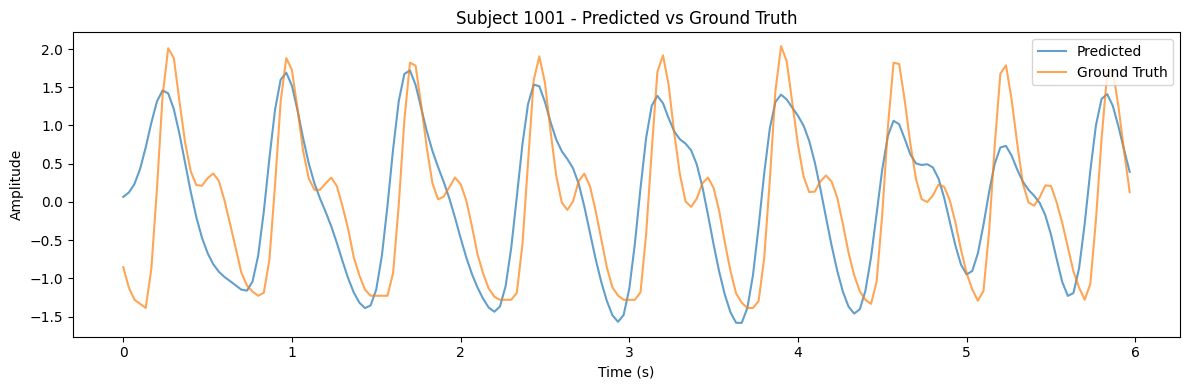

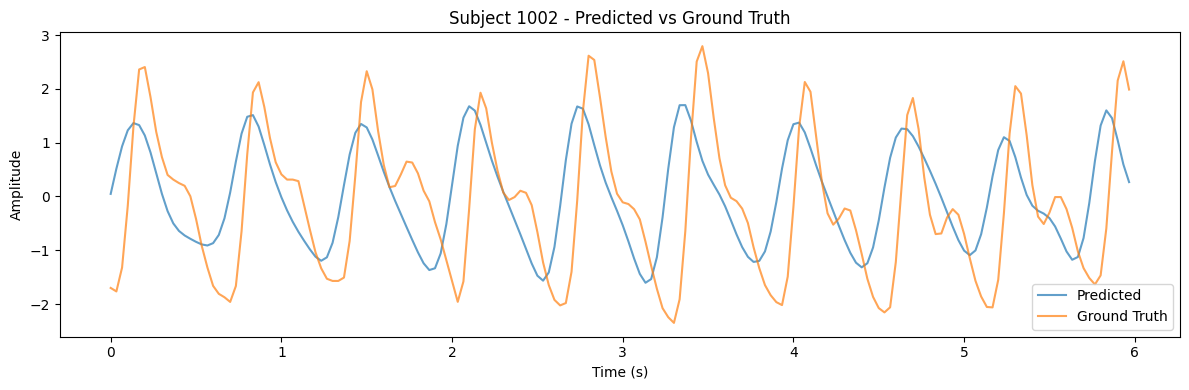

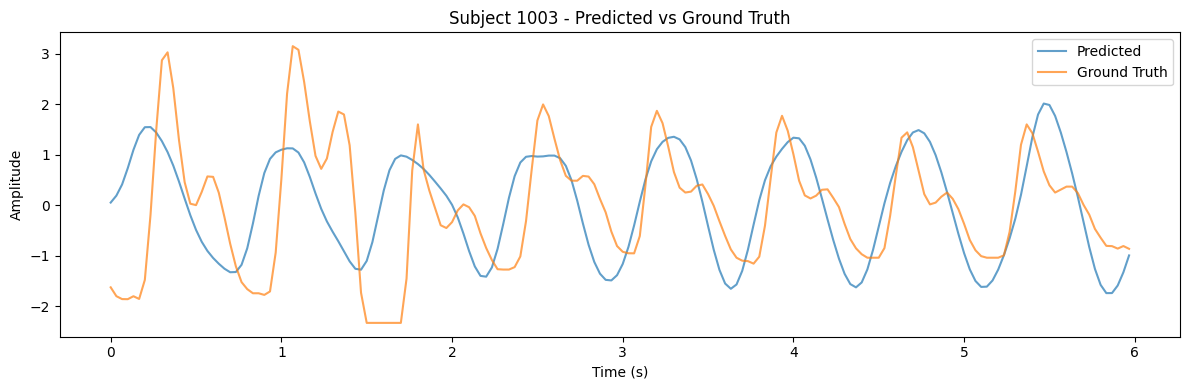

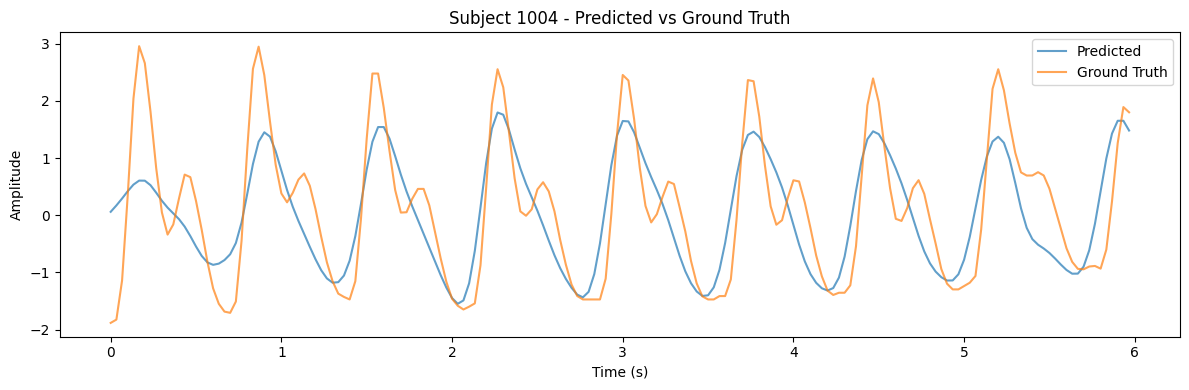

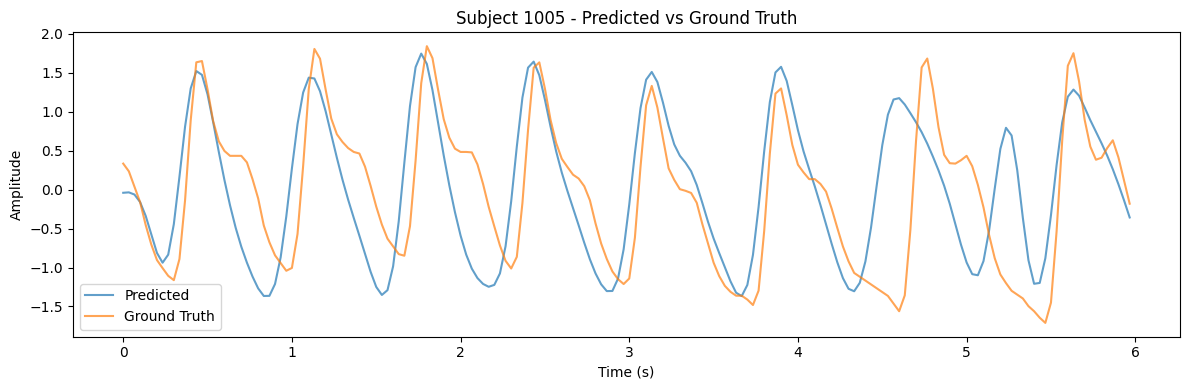

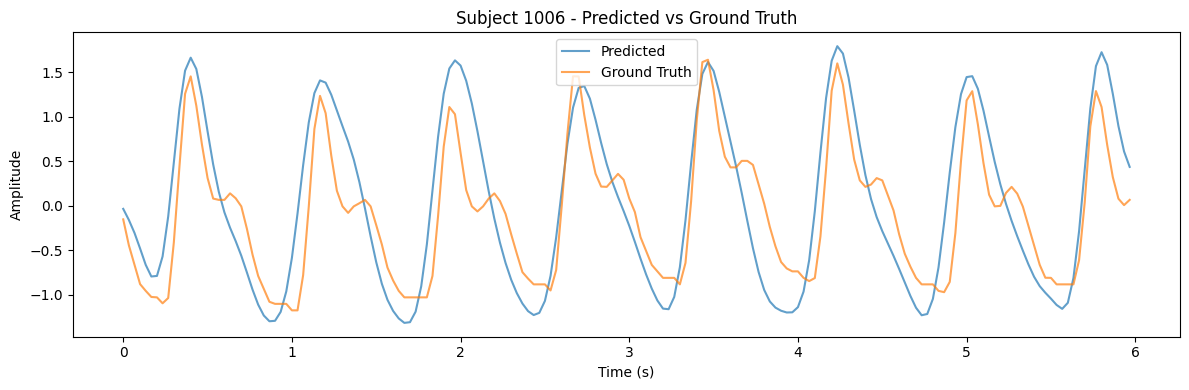

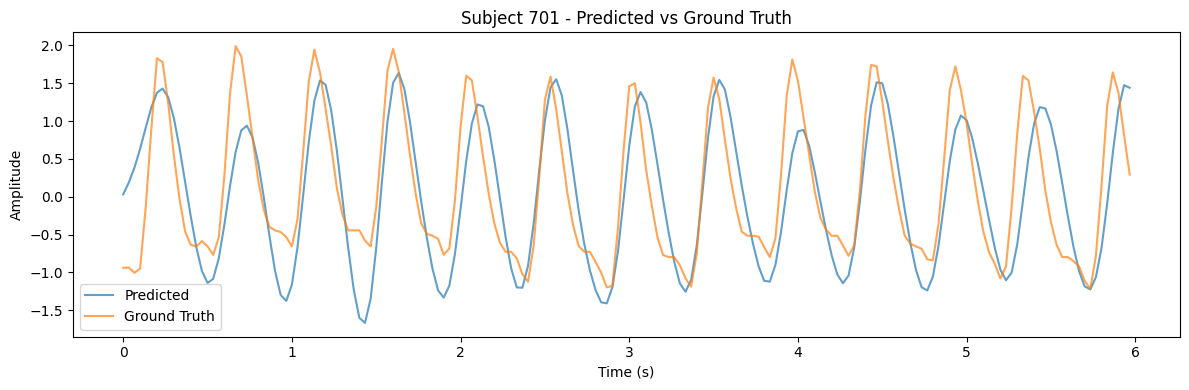

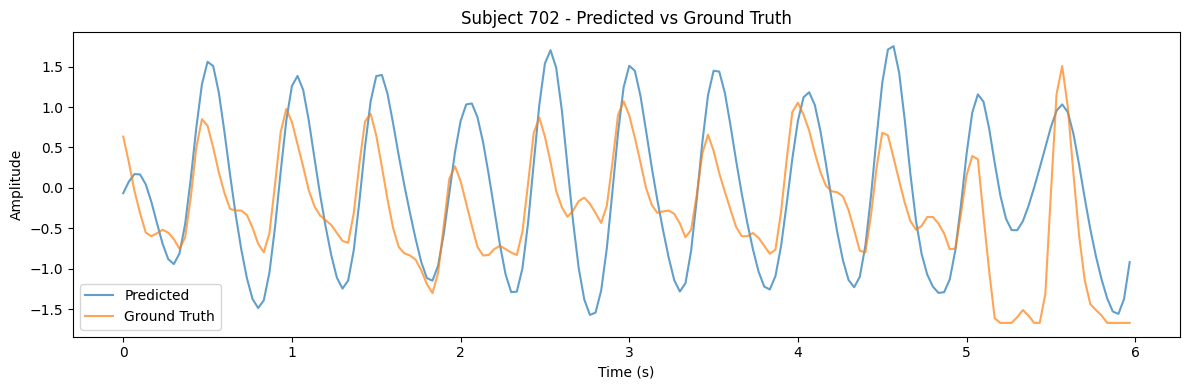

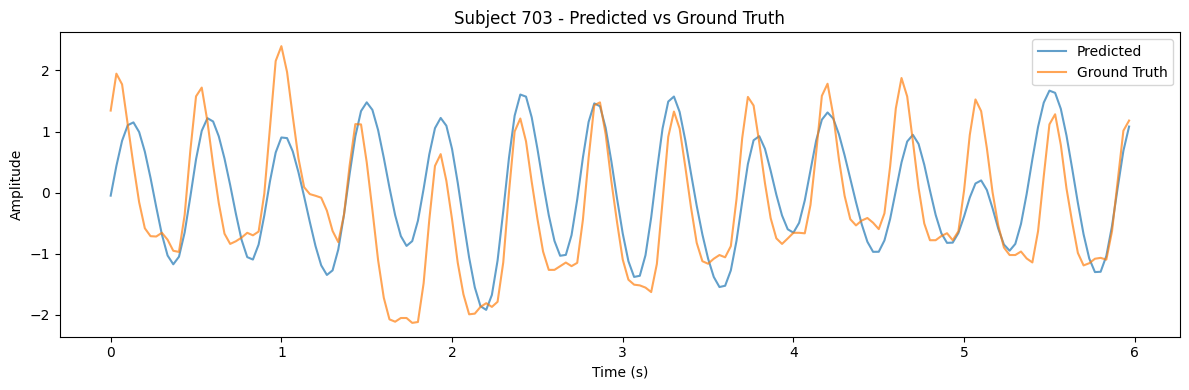

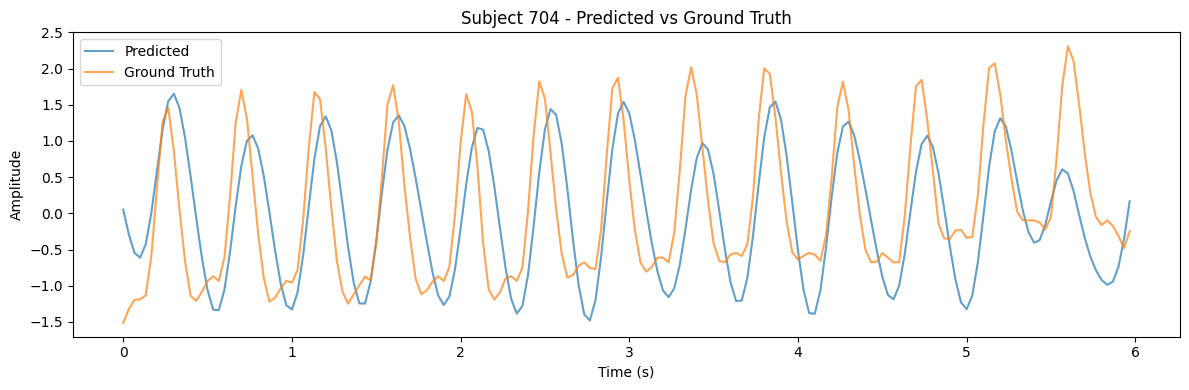

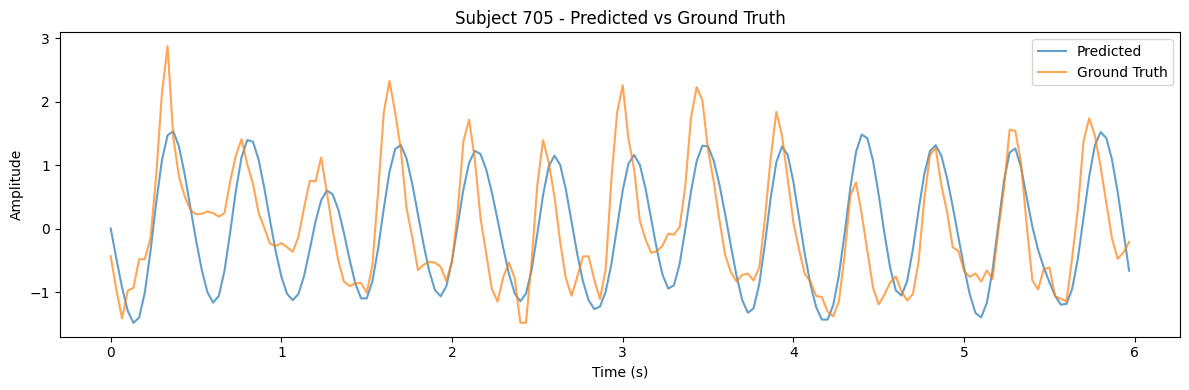

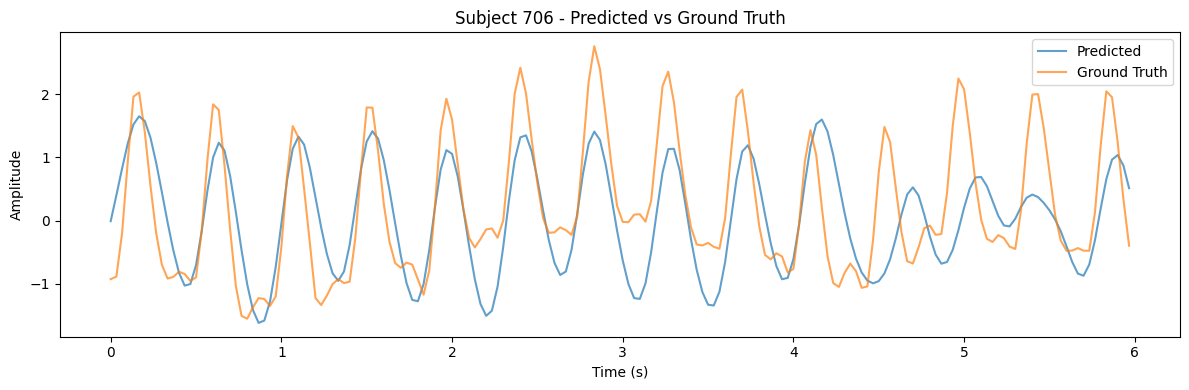

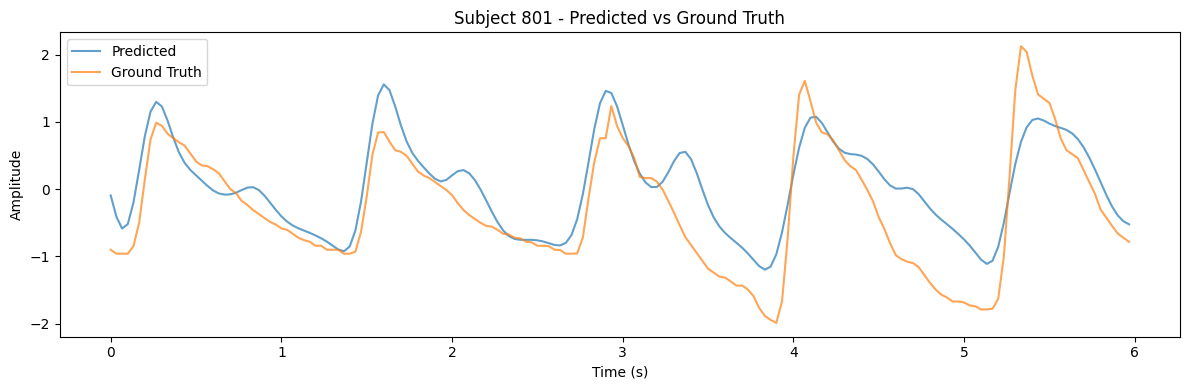

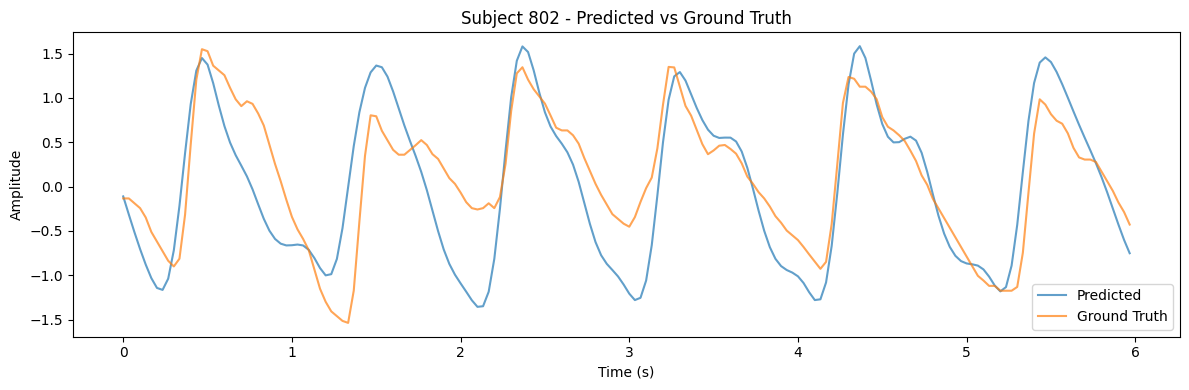

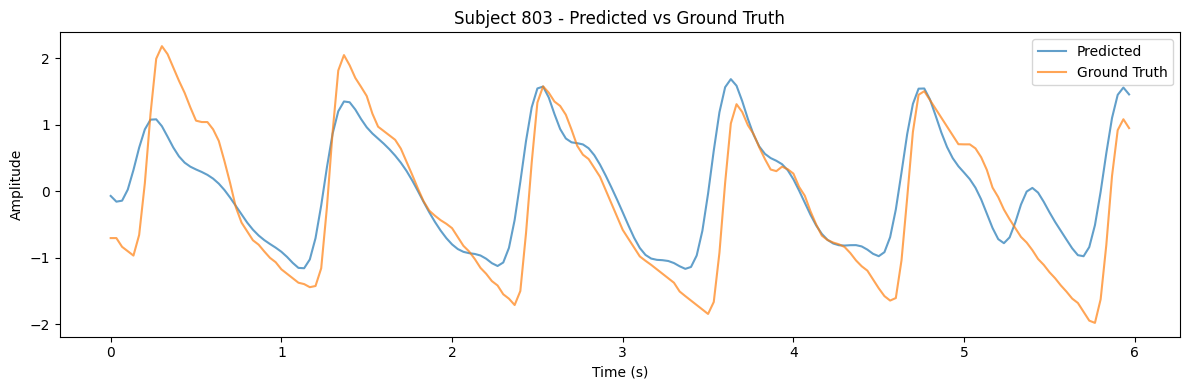

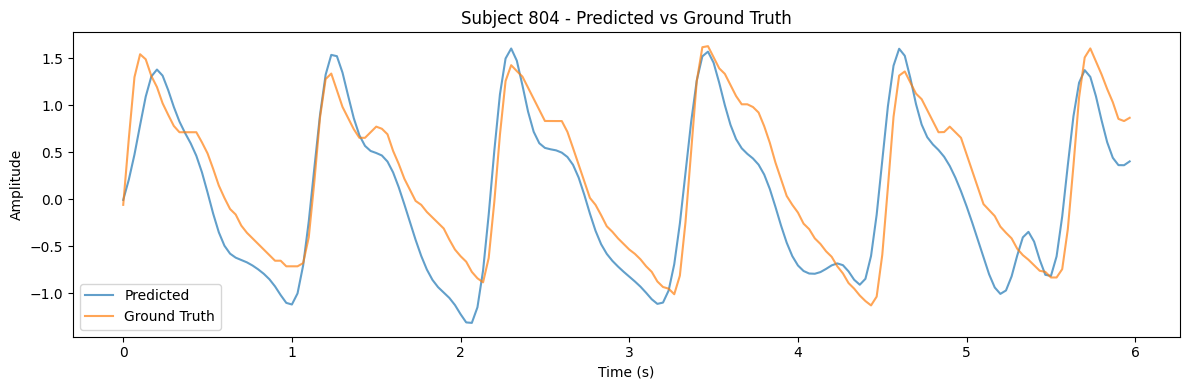

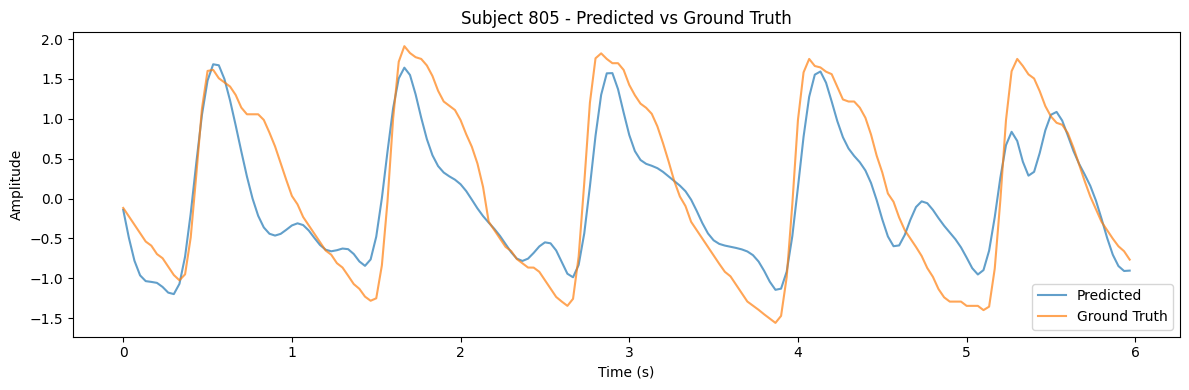

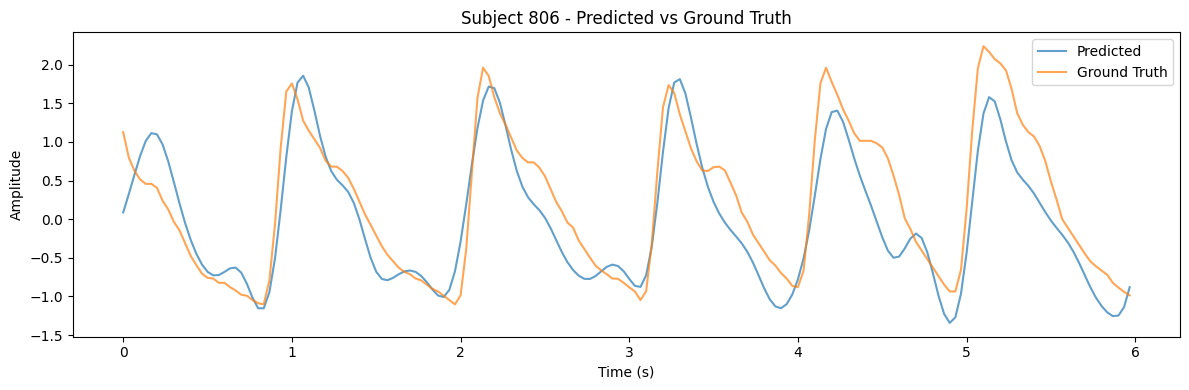

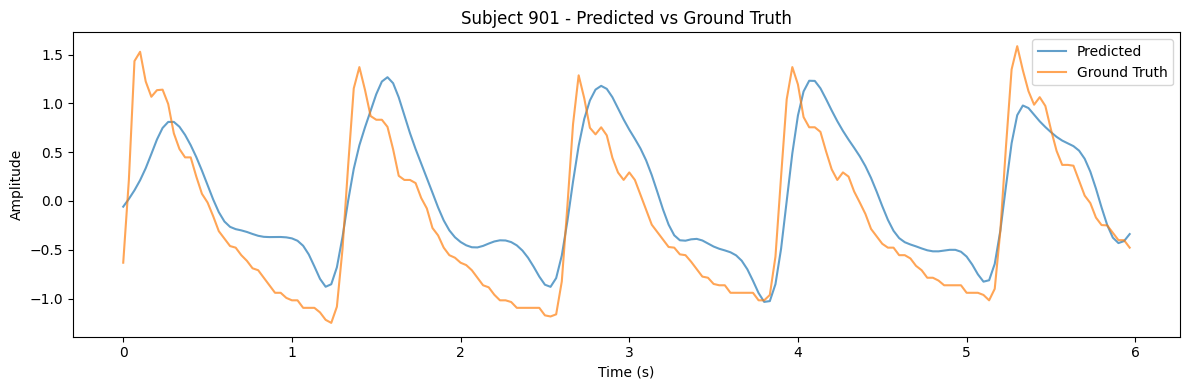

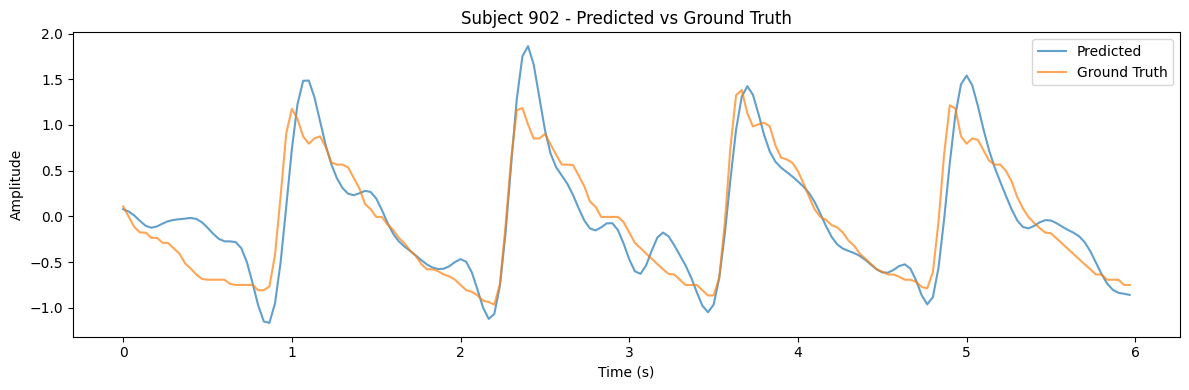

In [ ]:
# Plot waveforms for a few subjects
data = "/home/muhammadu/SS_Mamba/ss-mamba/runs/SSMamba_20260323_161551/signal_quality/waveforms.pt"  # Pure
waveforms = torch.load(data)
pd_1 = waveforms['pred_norm']
gt_1 = waveforms['gt']

fs = float(waveforms.get('fs', 30.0))  # samples per second
seconds_to_show = 6  # roughly 400 samples at 30 fps

for subj in sorted(set(pd_1.keys()) & set(gt_1.keys()))[:20]:  # plot first 20 subjects
    pred = reconstruct_subject_signal(pd_1[subj])
    gt = reconstruct_subject_signal(gt_1[subj])
    n = min(len(pred), len(gt))
    if n == 0:
        continue

    pred = pred[:n]
    gt = gt[:n]
    filtered_pred = bandpass_filter(pred, fs=fs, low=0.7, high=4.0, order=2)

    n_show = min(n, int(seconds_to_show * fs))
    t = np.arange(n_show) / fs  # time axis in seconds

    plt.figure(figsize=(12, 4))
    plt.plot(t, filtered_pred[:n_show], label='Predicted', color='blue')
    plt.plot(t, gt[:n_show], label='Ground Truth', color='red')
    plt.title(f'Subject {subj} - Predicted vs Ground Truth')
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.tight_layout()
    plt.show()

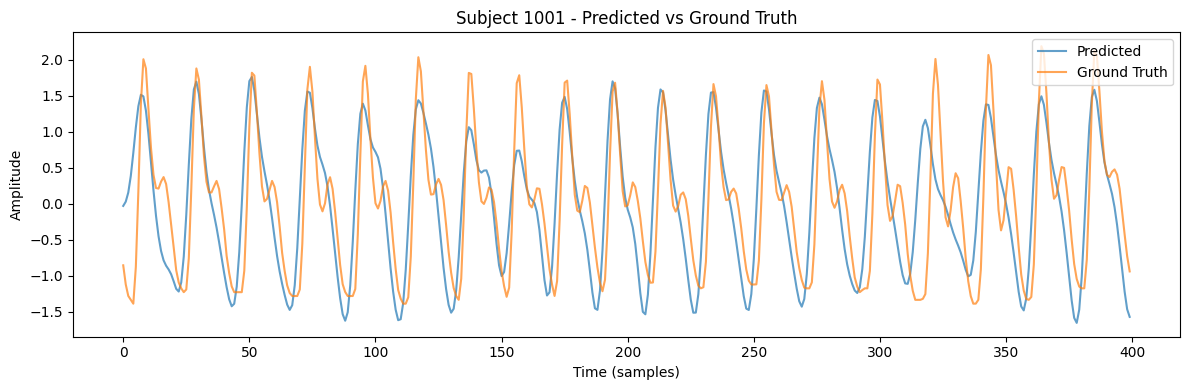

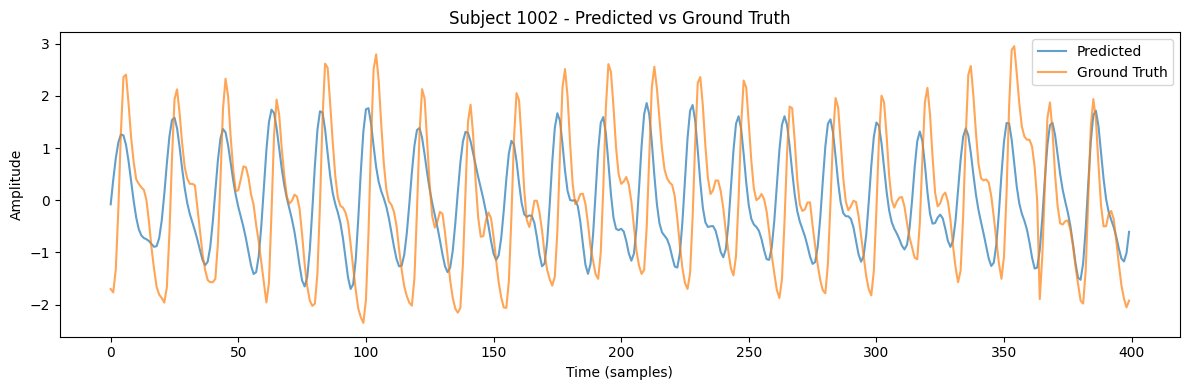

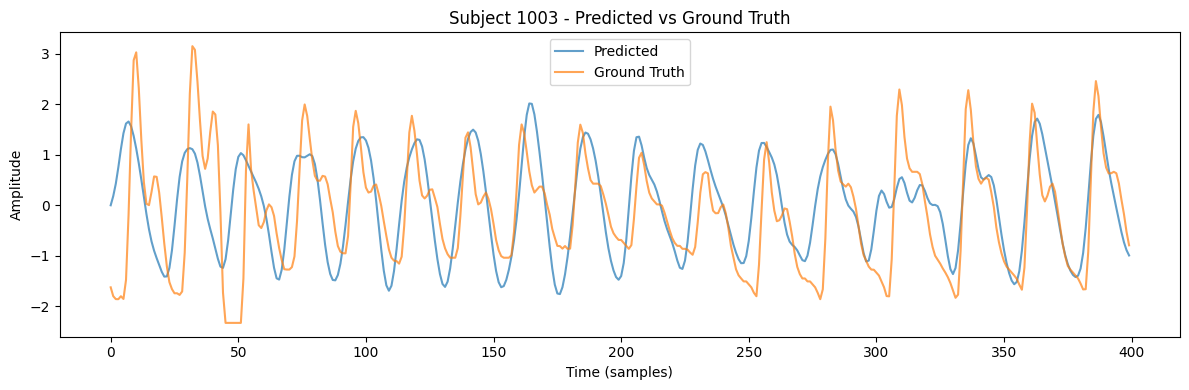

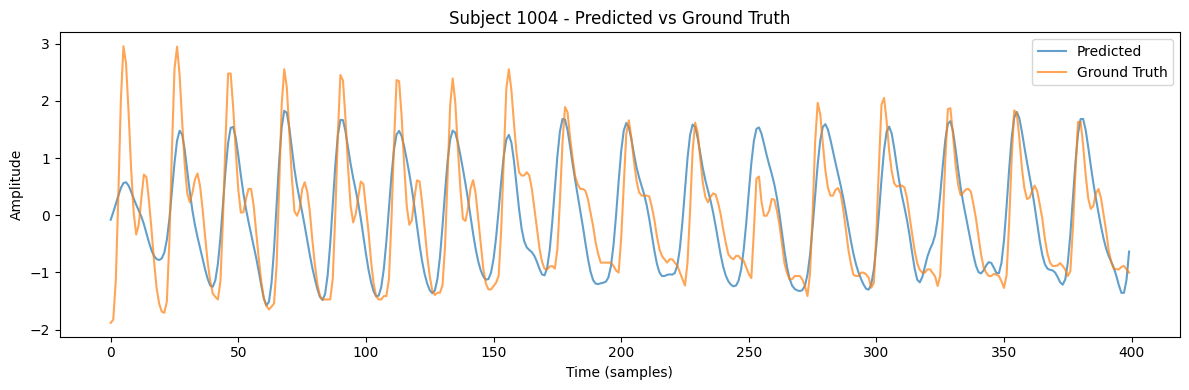

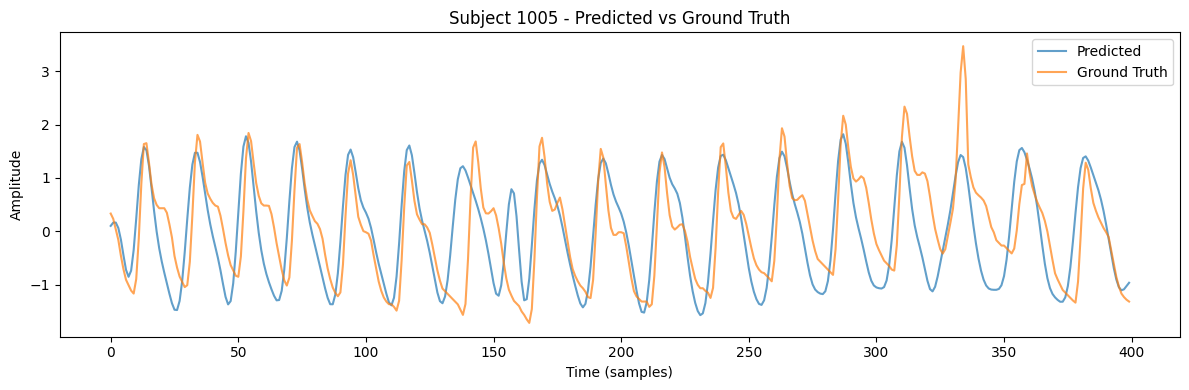

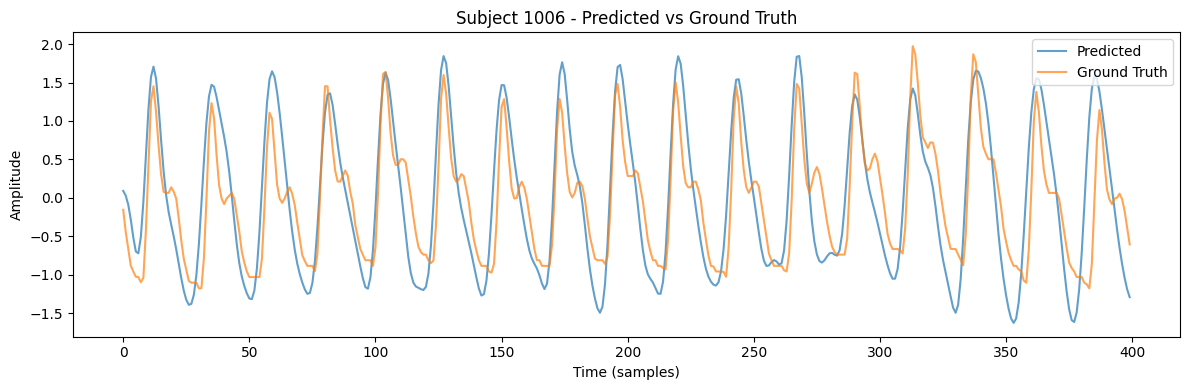

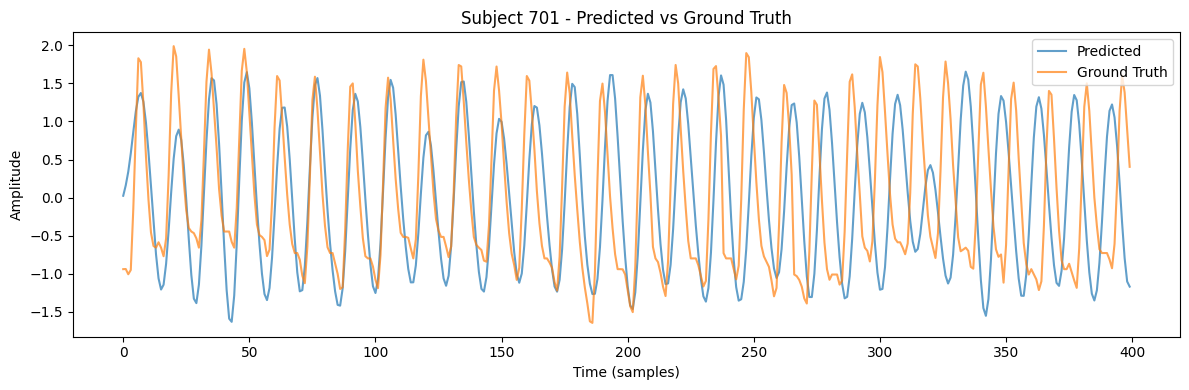

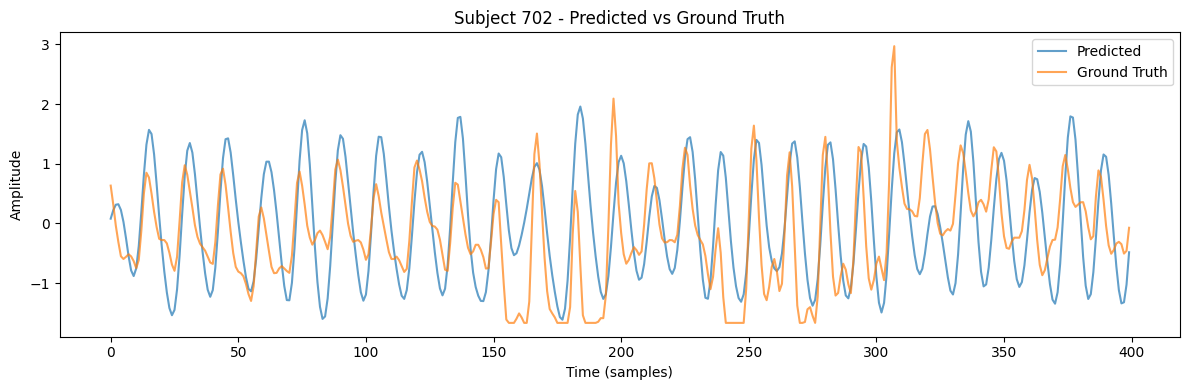

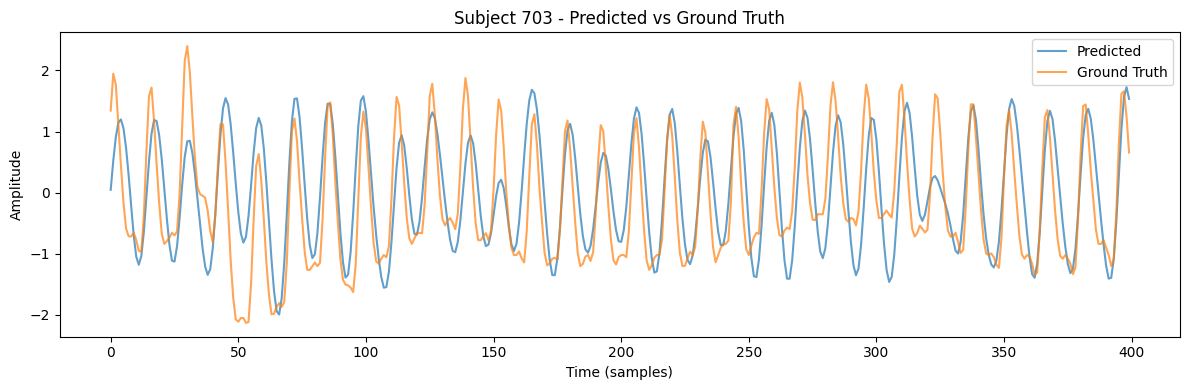

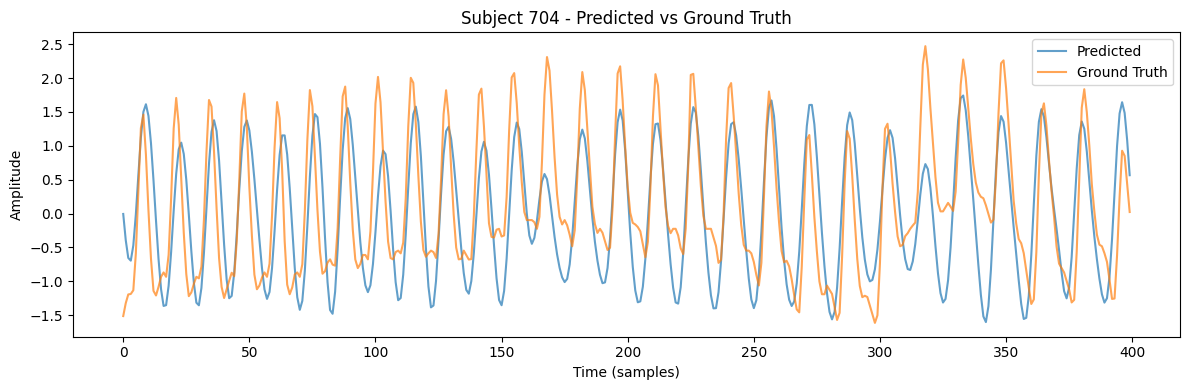

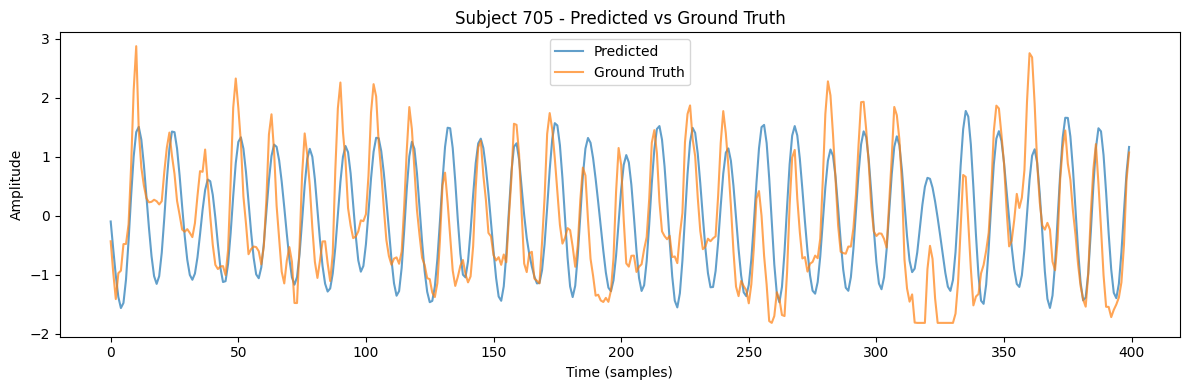

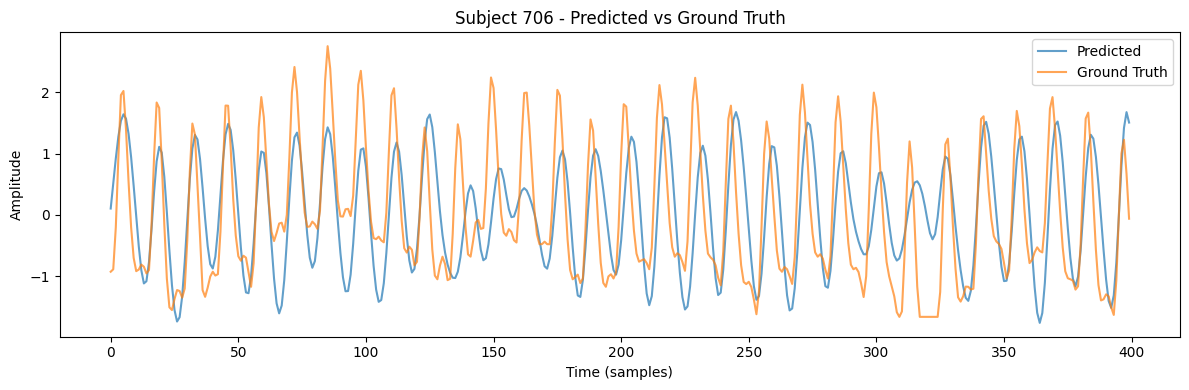

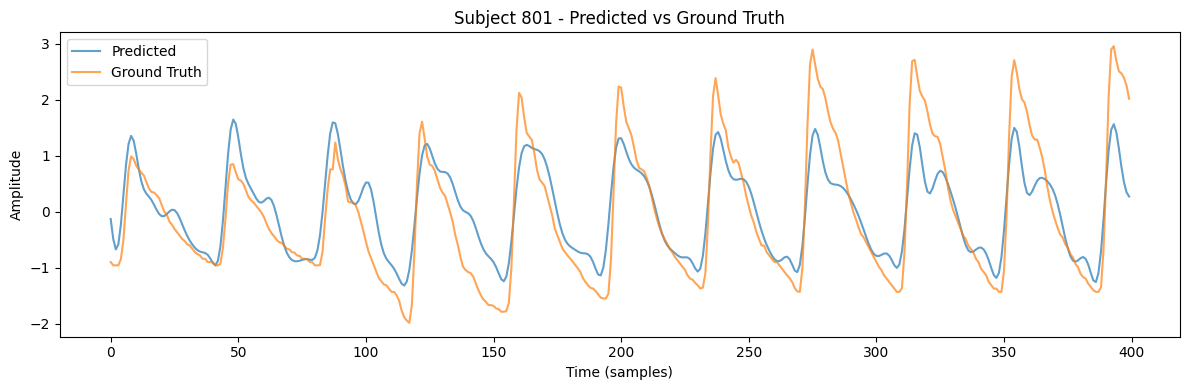

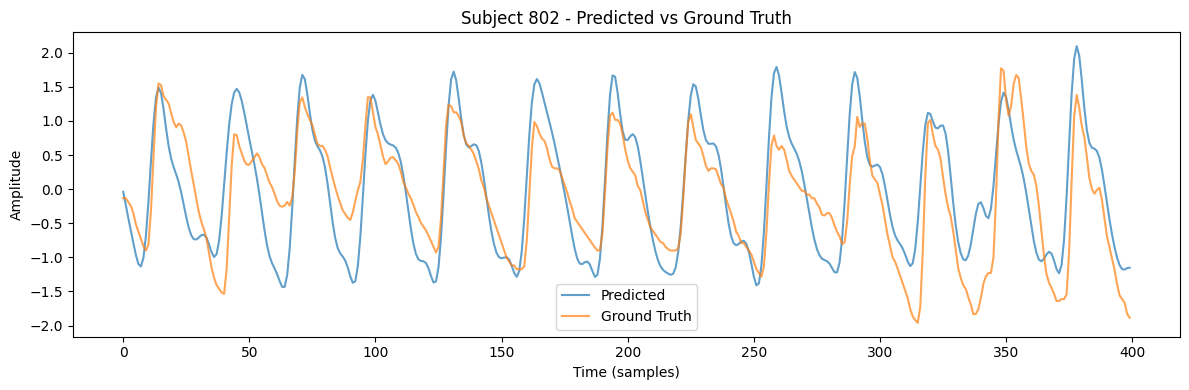

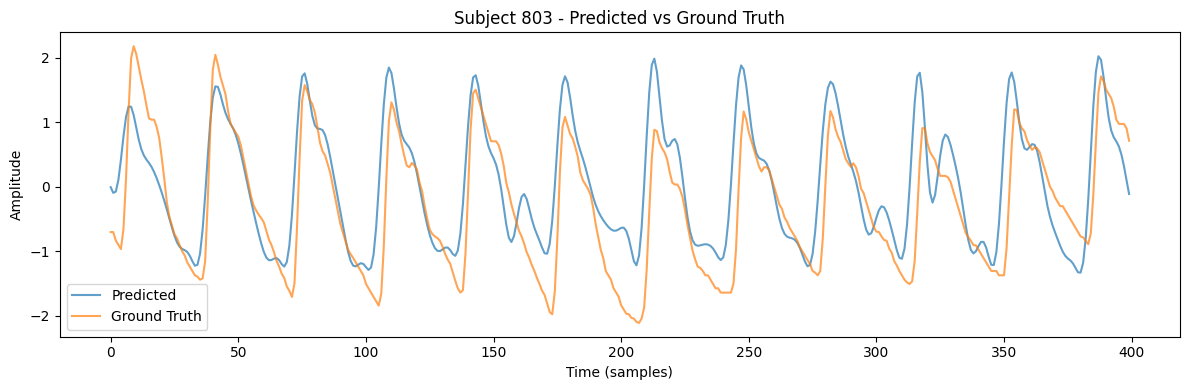

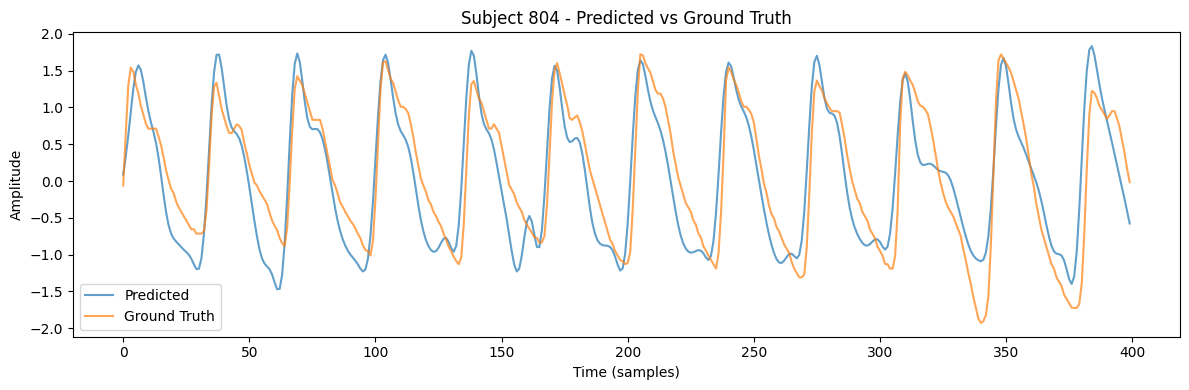

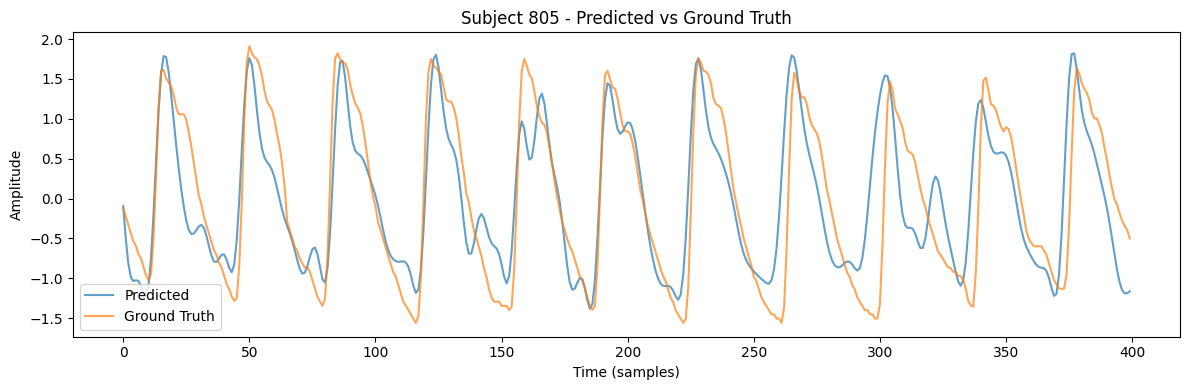

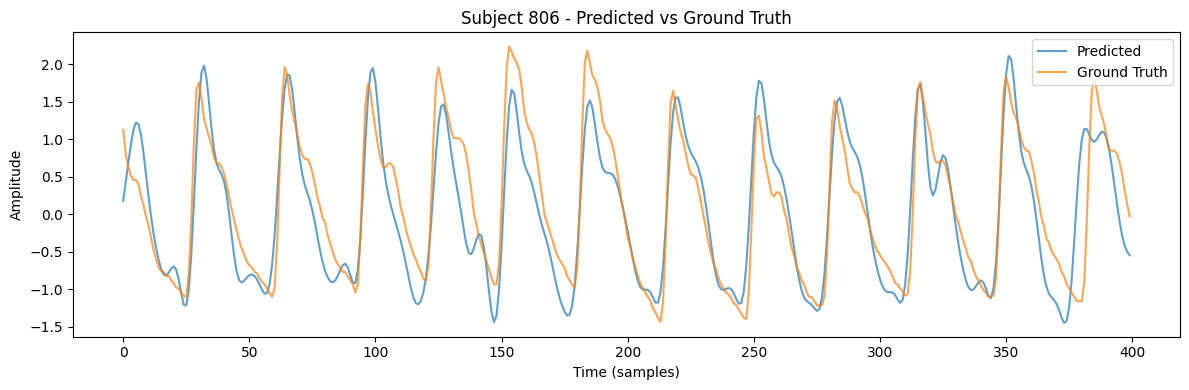

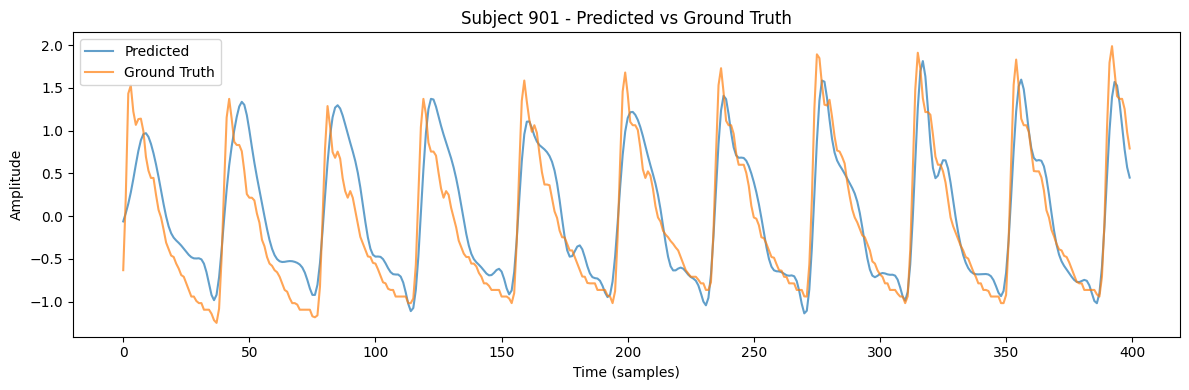

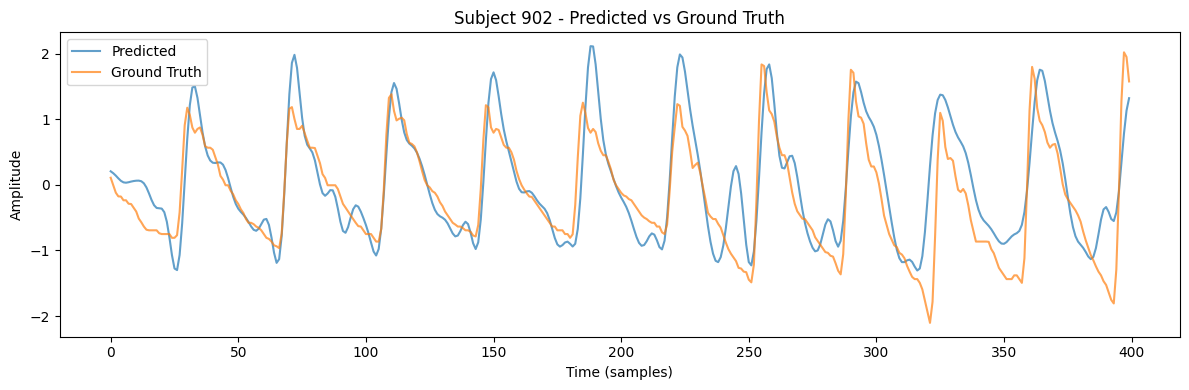

In [12]:
# Plot waveforms for a few subjects
data = "/home/muhammadu/SS_Mamba/ss-mamba/runs/SSMamba_20260323_161551/signal_quality/waveforms.pt" #Pure
# time in seconds = samples / fs, so 400 samples at 30 fps is ~13.3 seconds
waveforms = torch.load(data)
pd_1 = waveforms['pred_norm']
# filtered_pd_1 = {subj: bandpass_filter(reconstruct_subject_signal(chunks)) for subj, chunks in pd_1.items()}
gt_1 = waveforms['gt']

for subj in sorted(set(pd_1.keys()) & set(gt_1.keys()))[:20]:  # plot first 20 subjects
    pred = reconstruct_subject_signal(pd_1[subj])
    gt = reconstruct_subject_signal(gt_1[subj])
    n = min(len(pred), len(gt))
    if n == 0:
        continue
    pred = pred[:n]
    gt = gt[:n]
    filtered_pred = bandpass_filter(pred, fs=30.0, low=0.7, high=4.0, order=4)
    plt.figure(figsize=(12, 4))
    plt.plot(filtered_pred[:400], label='Predicted', alpha=0.7)
    plt.plot(gt[:400], label='Ground Truth', alpha=0.7)
    plt.title(f'Subject {subj} - Predicted vs Ground Truth')
    plt.xlabel('Time (samples)')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.tight_layout()
    plt.show()

## UBFC Dataset Signal Quality 
Compute Pearson Correlation Coefficient, DTW distance, SNR, PSD Correlation.
1) Predicted Signal
2) Subjectwise chunks

In [9]:
UBFC_path = "/home/muhammadu/SS_Mamba/ss-mamba/runs/SSMamba_20260324_080648/gt_pd/gt_pd.pt"
data = torch.load(UBFC_path, map_location=torch.device('cpu')  )
pd_1 = data["pd_1"]
gt_1 = data["gt_1"]
pd_1_raw = data["pd_1_raw"]

mean_p = []
mean_p_max = []
mean_dtw = []
mean_dtw_cost2 = []
mean_dtw_fast = []
mean_snr = []
mean_snr_si = []
mean_psd_corr = []

for i in range(len(pd_1)):
    pd_1_np = pd_1[i].detach().cpu().numpy().astype(np.float64).reshape(-1)
    gt_1_np = to_1d_numpy(gt_1[i])
    pd_1_raw_np = to_1d_numpy(pd_1_raw[i])

    pearson = pearson_corr(pd_1_np, gt_1_np)
    max_pearson = max_pearson_corr(pd_1_np, gt_1_np, max_lag=30)

    dtw = dtw_distance(pd_1_np, gt_1_np)
    dtw_cost2 = dtw_distance2(pd_1_np, gt_1_np)
    dtw_fast = fastdtw(pd_1_np, gt_1_np)[0]  # fastdtw returns (distance, path)

    snr = projection_snr_db(pd_1_np, gt_1_np)
    snr_si = si_snr(pd_1_np, gt_1_np)

    psd_correlation = psd_corr(pd_1_np, gt_1_np, fs=30.0)

    print(f"Subject {i}:")
    print(f"  Pearson Correlation Coefficient: {pearson:.4f}")
    print(f"  Max Pearson Correlation Coefficient: {max_pearson:.4f}")

    print(f"  DTW Distance: {dtw:.4f}")
    print(f"  DTW Distance cost2: {dtw_cost2:.4f}")
    # if isinstance(dtw_fast, tuple):
    #     dtw_fast = float(dtw_fast[0])  # fastdtw returns (distance, path)
    print(f"  DTW Distance fast: {dtw_fast:.4f}")
    print(f"  Projection SNR (dB): {snr:.4f}")
    print(f"  SI SNR (dB): {snr_si:.4f}")
    print(f"  PSD Correlation: {psd_correlation:.4f}")
    
    mean_p.append(pearson)
    mean_p_max.append(max_pearson)

    mean_dtw.append(dtw)
    mean_dtw_cost2.append(dtw_cost2)
    mean_dtw_fast.append(dtw_fast)

    mean_snr.append(snr)
    mean_snr_si.append(snr_si)

    mean_psd_corr.append(psd_correlation)

print('---------Mean Metrics---------')
print(f"Mean Pearson Correlation Coefficient: {np.nanmean(mean_p):.4f}")
print(f"Mean Max Pearson Correlation Coefficient: {np.nanmean(mean_p_max):.4f}")
print(f"Mean DTW Distance: {np.nanmean(mean_dtw):.4f}")
print(f"Mean DTW Distance cost2: {np.nanmean(mean_dtw_cost2):.4f}")
print(f"Mean DTW Distance fast: {np.nanmean(mean_dtw_fast):.4f}")
print(f"Mean Projection SNR (dB): {np.nanmean(mean_snr):.4f}")
print(f"Mean SI SNR (dB): {np.nanmean(mean_snr_si):.4f}")
print(f"Mean PSD Correlation: {np.nanmean(mean_psd_corr):.4f}")


Subject 0:
  Pearson Correlation Coefficient: 0.6068
  Max Pearson Correlation Coefficient: 0.6294
  DTW Distance: 114.7858
  DTW Distance cost2: 62.6016
  DTW Distance fast: 168.8265
  Projection SNR (dB): -3.4974
  SI SNR (dB): -2.3443
  PSD Correlation: 0.2587
Subject 1:
  Pearson Correlation Coefficient: 0.6782
  Max Pearson Correlation Coefficient: 0.7868
  DTW Distance: 105.9795
  DTW Distance cost2: 67.6806
  DTW Distance fast: 114.2831
  Projection SNR (dB): -0.8057
  SI SNR (dB): -0.6961
  PSD Correlation: 0.6575
Subject 2:
  Pearson Correlation Coefficient: 0.8885
  Max Pearson Correlation Coefficient: 0.8885
  DTW Distance: 75.9075
  DTW Distance cost2: 26.6666
  DTW Distance fast: 124.7639
  Projection SNR (dB): 5.3658
  SI SNR (dB): 5.7400
  PSD Correlation: 0.7336
Subject 3:
  Pearson Correlation Coefficient: 0.6873
  Max Pearson Correlation Coefficient: 0.7640
  DTW Distance: 105.5554
  DTW Distance cost2: 49.9946
  DTW Distance fast: 120.0744
  Projection SNR (dB): -0.6

### 2) Subjectwise chunks UBFC

In [ ]:
data = "/home/muhammadu/SS_Mamba/ss-mamba/runs/SSMamba_20260324_080648/signal_quality/waveforms.pt"
waveforms = torch.load(data)
pd_1 = waveforms['pred_norm']
gt_1 = waveforms['gt']
# pred_norm and gt in waveforms.pt are dicts (subject -> chunk dict), not arrays

mean_p = []
mean_p_max = []
mean_dtw = []
mean_dtw_cost2 = []
mean_dtw_fast = []
mean_snr = []
mean_snr_si = []
mean_psd_corr = []

for subj in sorted(set(pd_1.keys()) & set(gt_1.keys())):
    pred = reconstruct_subject_signal(pd_1[subj])
    gt = reconstruct_subject_signal(gt_1[subj])
    n = min(len(pred), len(gt))
    # print(f"Subject {len(subj)}")
    print(f"Subject {subj} - Length: {n}")
    if n == 0:
        continue
    pred = pred[:n]
    gt = gt[:n]
    pearson = pearson_corr(pred, gt)
    max_pearson = max_pearson_corr(pred, gt, max_lag=30)

    dtw = dtw_distance(pred, gt)
    dtw_cost2 = dtw_distance2(pred, gt)
    dtw_fast = fastdtw(pred, gt)[0]  # fastdtw returns (distance, path)

    snr = projection_snr_db(pred, gt)
    snr_si = si_snr(pred, gt)

    psd_correlation = psd_corr(pred, gt, fs=30.0)

    # print(f"Subject {subj}:")
    print(f"  Pearson Correlation Coefficient: {pearson:.4f}")
    print(f"  Max Pearson Correlation Coefficient: {max_pearson:.4f}")

    print(f"  DTW Distance: {dtw:.4f}")
    print(f"  DTW Distance cost2: {dtw_cost2:.4f}")
    # if isinstance(dtw_fast, tuple):
    #     dtw_fast = float(dtw_fast[0])  # fastdtw returns (distance, path)
    print(f"  DTW Distance fast: {dtw_fast:.4f}")
    print(f"  Projection SNR (dB): {snr:.4f}")
    print(f"  SI SNR (dB): {snr_si:.4f}")
    print(f"  PSD Correlation: {psd_correlation:.4f}")
    
    mean_p.append(pearson)
    mean_p_max.append(max_pearson)

    mean_dtw.append(dtw)
    mean_dtw_cost2.append(dtw_cost2)
    mean_dtw_fast.append(dtw_fast)

    mean_snr.append(snr)
    mean_snr_si.append(snr_si)

    mean_psd_corr.append(psd_correlation)

print('---------Mean Metrics (Subject-wise)---------')
# print('Total subjects:', len(subj))
print(f"Mean Pearson Correlation Coefficient: {np.nanmean(mean_p):.4f}")
print(f"Mean Max Pearson Correlation Coefficient: {np.nanmean(mean_p_max):.4f}")
print(f"Mean DTW Distance: {np.nanmean(mean_dtw):.4f}")
print(f"Mean DTW Distance cost2: {np.nanmean(mean_dtw_cost2):.4f}")
print(f"Mean DTW Distance fast: {np.nanmean(mean_dtw_fast):.4f}")
print(f"Mean Projection SNR (dB): {np.nanmean(mean_snr):.4f}")
print(f"Mean SI SNR (dB): {np.nanmean(mean_snr_si):.4f}")
print(f"Mean PSD Correlation: {np.nanmean(mean_psd_corr):.4f}")

Subject 9
Subject subject41 - Length: 1920
Subject subject41:
  Pearson Correlation Coefficient: 0.7387
  Max Pearson Correlation Coefficient: 0.7471
  DTW Distance: 572.1241
  DTW Distance cost2: 275.9018
  DTW Distance fast: 913.0231
  Projection SNR (dB): 0.7908
  SI SNR (dB): 0.7947
  PSD Correlation: 0.9376
Subject 9
Subject subject42 - Length: 1920
Subject subject42:
  Pearson Correlation Coefficient: 0.8247
  Max Pearson Correlation Coefficient: 0.8419
  DTW Distance: 528.9534
  DTW Distance cost2: 260.0041
  DTW Distance fast: 854.6126
  Projection SNR (dB): 3.2765
  SI SNR (dB): 3.2769
  PSD Correlation: 0.9764
Subject 9
Subject subject43 - Length: 1920
Subject subject43:
  Pearson Correlation Coefficient: 0.7783
  Max Pearson Correlation Coefficient: 0.8076
  DTW Distance: 512.6066
  DTW Distance cost2: 242.1896
  DTW Distance fast: 734.6154
  Projection SNR (dB): 1.8660
  SI SNR (dB): 1.8660
  PSD Correlation: 0.9832
Subject 9
Subject subject44 - Length: 1920
Subject subject

## MMPD Dataset Signal Quality 
Compute Pearson Correlation Coefficient, DTW distance, SNR, PSD Correlation.
1) Predicted Signal
2) Subjectwise chunks

In [10]:
MMPD_path = "/home/muhammadu/SS_Mamba/ss-mamba/runs/SSMamba_20260324_120457/gt_pd/gt_pd.pt"
data = torch.load(MMPD_path, map_location=torch.device('cpu')  )
pd_1 = data["pd_1"]
gt_1 = data["gt_1"]
pd_1_raw = data["pd_1_raw"]

mean_p = []
mean_p_max = []
mean_dtw = []
mean_dtw_cost2 = []
mean_dtw_fast = []
mean_snr = []
mean_snr_si = []
mean_psd_corr = []

for i in range(len(pd_1)):
    pd_1_np = pd_1[i].detach().cpu().numpy().astype(np.float64).reshape(-1)
    gt_1_np = to_1d_numpy(gt_1[i])
    pd_1_raw_np = to_1d_numpy(pd_1_raw[i])

    pearson = pearson_corr(pd_1_np, gt_1_np)
    max_pearson = max_pearson_corr(pd_1_np, gt_1_np, max_lag=30)

    dtw = dtw_distance(pd_1_np, gt_1_np)
    dtw_cost2 = dtw_distance2(pd_1_np, gt_1_np)
    dtw_fast = fastdtw(pd_1_np, gt_1_np)[0]  # fastdtw returns (distance, path)

    snr = projection_snr_db(pd_1_np, gt_1_np)
    snr_si = si_snr(pd_1_np, gt_1_np)

    psd_correlation = psd_corr(pd_1_np, gt_1_np, fs=30.0)

    print(f"Subject {i}:")
    print(f"  Pearson Correlation Coefficient: {pearson:.4f}")
    print(f"  Max Pearson Correlation Coefficient: {max_pearson:.4f}")

    print(f"  DTW Distance: {dtw:.4f}")
    print(f"  DTW Distance cost2: {dtw_cost2:.4f}")
    # if isinstance(dtw_fast, tuple):
    #     dtw_fast = float(dtw_fast[0])  # fastdtw returns (distance, path)
    print(f"  DTW Distance fast: {dtw_fast:.4f}")
    print(f"  Projection SNR (dB): {snr:.4f}")
    print(f"  SI SNR (dB): {snr_si:.4f}")
    print(f"  PSD Correlation: {psd_correlation:.4f}")
    
    mean_p.append(pearson)
    mean_p_max.append(max_pearson)

    mean_dtw.append(dtw)
    mean_dtw_cost2.append(dtw_cost2)
    mean_dtw_fast.append(dtw_fast)

    mean_snr.append(snr)
    mean_snr_si.append(snr_si)

    mean_psd_corr.append(psd_correlation)

print('---------Mean Metrics---------')
print(f"Mean Pearson Correlation Coefficient: {np.nanmean(mean_p):.4f}")
print(f"Mean Max Pearson Correlation Coefficient: {np.nanmean(mean_p_max):.4f}")
print(f"Mean DTW Distance: {np.nanmean(mean_dtw):.4f}")
print(f"Mean DTW Distance cost2: {np.nanmean(mean_dtw_cost2):.4f}")
print(f"Mean DTW Distance fast: {np.nanmean(mean_dtw_fast):.4f}")
print(f"Mean Projection SNR (dB): {np.nanmean(mean_snr):.4f}")
print(f"Mean SI SNR (dB): {np.nanmean(mean_snr_si):.4f}")
print(f"Mean PSD Correlation: {np.nanmean(mean_psd_corr):.4f}")


Subject 0:
  Pearson Correlation Coefficient: 0.5865
  Max Pearson Correlation Coefficient: 0.5865
  DTW Distance: 466.2893
  DTW Distance cost2: 296.7385
  DTW Distance fast: 1200.9420
  Projection SNR (dB): -2.9060
  SI SNR (dB): -2.8028
  PSD Correlation: 0.9609
Subject 1:
  Pearson Correlation Coefficient: 0.7975
  Max Pearson Correlation Coefficient: 0.8062
  DTW Distance: 334.4950
  DTW Distance cost2: 155.9100
  DTW Distance fast: 739.7335
  Projection SNR (dB): 2.2157
  SI SNR (dB): 2.4246
  PSD Correlation: 0.9384
Subject 2:
  Pearson Correlation Coefficient: 0.7412
  Max Pearson Correlation Coefficient: 0.8230
  DTW Distance: 331.7946
  DTW Distance cost2: 161.1889
  DTW Distance fast: 508.5399
  Projection SNR (dB): 0.8613
  SI SNR (dB): 0.8617
  PSD Correlation: 0.8952
Subject 3:
  Pearson Correlation Coefficient: 0.5474
  Max Pearson Correlation Coefficient: 0.5539
  DTW Distance: 430.9305
  DTW Distance cost2: 249.4336
  DTW Distance fast: 601.6351
  Projection SNR (dB): 

### 2) Subject-wise chunks

In [17]:
data = "/home/muhammadu/SS_Mamba/ss-mamba/runs/SSMamba_20260324_120457/signal_quality/waveforms.pt" # MMPD

waveforms = torch.load(data)
pd_1 = waveforms['pred_norm']
gt_1 = waveforms['gt']
# pred_norm and gt in waveforms.pt are dicts (subject -> chunk dict), not arrays

mean_p = []
mean_p_max = []
mean_dtw = []
mean_dtw_cost2 = []
mean_dtw_fast = []
mean_snr = []
mean_snr_si = []
mean_psd_corr = []

for subj in sorted(set(pd_1.keys()) & set(gt_1.keys())):
    pred = reconstruct_subject_signal(pd_1[subj])
    gt = reconstruct_subject_signal(gt_1[subj])
    n = min(len(pred), len(gt))
    # print(f"Subject {len(subj)}")
    print(f"Subject {subj} - Length: {n}")
    if n == 0:
        continue
    pred = pred[:n]
    gt = gt[:n]
    pearson = pearson_corr(pred, gt)
    max_pearson = max_pearson_corr(pred, gt, max_lag=30)

    dtw = dtw_distance(pred, gt)
    dtw_cost2 = dtw_distance2(pred, gt)
    dtw_fast = fastdtw(pred, gt)[0]  # fastdtw returns (distance, path)

    snr = projection_snr_db(pred, gt)
    snr_si = si_snr(pred, gt)

    psd_correlation = psd_corr(pred, gt, fs=30.0)

    # print(f"Subject {subj}:")
    print(f"  Pearson Correlation Coefficient: {pearson:.4f}")
    print(f"  Max Pearson Correlation Coefficient: {max_pearson:.4f}")

    print(f"  DTW Distance: {dtw:.4f}")
    print(f"  DTW Distance cost2: {dtw_cost2:.4f}")
    # if isinstance(dtw_fast, tuple):
    #     dtw_fast = float(dtw_fast[0])  # fastdtw returns (distance, path)
    print(f"  DTW Distance fast: {dtw_fast:.4f}")
    print(f"  Projection SNR (dB): {snr:.4f}")
    print(f"  SI SNR (dB): {snr_si:.4f}")
    print(f"  PSD Correlation: {psd_correlation:.4f}")
    
    mean_p.append(pearson)
    mean_p_max.append(max_pearson)

    mean_dtw.append(dtw)
    mean_dtw_cost2.append(dtw_cost2)
    mean_dtw_fast.append(dtw_fast)

    mean_snr.append(snr)
    mean_snr_si.append(snr_si)

    mean_psd_corr.append(psd_correlation)

print('---------Mean Metrics (Subject-wise)---------')
# print('Total subjects:', len(subj))
print(f"Mean Pearson Correlation Coefficient: {np.nanmean(mean_p):.4f}")
print(f"Mean Max Pearson Correlation Coefficient: {np.nanmean(mean_p_max):.4f}")
print(f"Mean DTW Distance: {np.nanmean(mean_dtw):.4f}")
print(f"Mean DTW Distance cost2: {np.nanmean(mean_dtw_cost2):.4f}")
print(f"Mean DTW Distance fast: {np.nanmean(mean_dtw_fast):.4f}")
print(f"Mean Projection SNR (dB): {np.nanmean(mean_snr):.4f}")
print(f"Mean SI SNR (dB): {np.nanmean(mean_snr_si):.4f}")
print(f"Mean PSD Correlation: {np.nanmean(mean_psd_corr):.4f}")

Subject subject27_L1_MO1_E1_S3_GE2_GL2_H2_MA1 - Length: 1760
  Pearson Correlation Coefficient: 0.6435
  Max Pearson Correlation Coefficient: 0.6435
  DTW Distance: 583.5451
  DTW Distance cost2: 347.3957
  DTW Distance fast: 1303.3898
  Projection SNR (dB): -1.5071
  SI SNR (dB): -1.5065
  PSD Correlation: 0.9675
Subject subject27_L1_MO1_E2_S3_GE2_GL2_H2_MA1 - Length: 1760
  Pearson Correlation Coefficient: 0.7487
  Max Pearson Correlation Coefficient: 0.8169
  DTW Distance: 453.6225
  DTW Distance cost2: 217.7233
  DTW Distance fast: 715.9018
  Projection SNR (dB): 1.0559
  SI SNR (dB): 1.0561
  PSD Correlation: 0.8744
Subject subject27_L1_MO2_E2_S3_GE2_GL2_H2_MA1 - Length: 1760
  Pearson Correlation Coefficient: 0.6189
  Max Pearson Correlation Coefficient: 0.6232
  DTW Distance: 567.1591
  DTW Distance cost2: 319.7732
  DTW Distance fast: 853.5075
  Projection SNR (dB): -2.0704
  SI SNR (dB): -2.0704
  PSD Correlation: 0.7033
Subject subject27_L1_MO3_E2_S3_GE2_GL2_H2_MA1 - Length: 

In [50]:
data = "/home/muhammadu/SS_Mamba/ss-mamba/runs/SSMamba_20260324_080648/signal_quality/waveforms.pt"
waveforms = torch.load(data)
pd_1 = waveforms['pred_norm']
gt_1 = waveforms['gt']
# pred_norm and gt in waveforms.pt are dicts (subject -> chunk dict), not arrays
if isinstance(pd_1, dict) and isinstance(gt_1, dict):
    common_subjects = sorted(set(pd_1.keys()) & set(gt_1.keys()))
    print(f"pd_1 subjects: {len(pd_1)}, gt_1 subjects: {len(gt_1)}, common: {len(common_subjects)}")

    if common_subjects:
        s = common_subjects[0]
        pd_1_np = reconstruct_subject_signal(pd_1[s])
        gt_1_np = reconstruct_subject_signal(gt_1[s])
        print(f"example subject: {s}")
        print("shapes:", pd_1_np.shape, gt_1_np.shape)
else:
    print("shapes:", np.asarray(pd_1).shape, np.asarray(gt_1).shape)

pd_1 subjects: 12, gt_1 subjects: 12, common: 12
example subject: subject41
shapes: (1920,) (1920,)


In [7]:
# pure_path = "/home/muhammadu/SS_Mamba/ss-mamba/runs/SSMamba_20260323_161551/gt_pd/gt_pd.pt"
pure_path = "/home/muhammadu/SS_Mamba/ss-mamba/runs/SSMamba_20260324_080648/gt_pd/gt_pd.pt"
pure_data = torch.load(pure_path, map_location=torch.device('cpu')  )
pd_1 = pure_data["pd_1"]
gt_1 = pure_data["gt_1"]
pd_1_raw = pure_data["pd_1_raw"]


In [ ]:
for i in range(len(pd_1)):
    print(f"pd_1[{i}]: {pd_1[i].shape}")

(22560,)


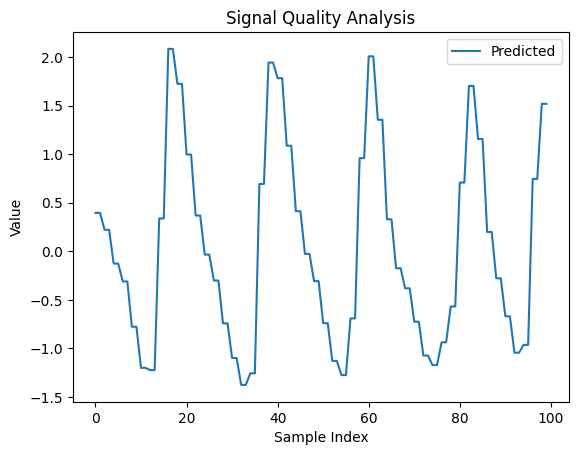

In [9]:
# reshape to 1D numpy
if isinstance(pd_1, list):
    pd_1_numpy = np.concatenate(
        [x.detach().cpu().numpy().astype(np.float64).reshape(-1) for x in pd_1]
    )
else:
    pd_1_numpy = np.asarray(
        pd_1.detach().cpu().numpy() if torch.is_tensor(pd_1) else pd_1,
        dtype=np.float64
    ).reshape(-1)
print(pd_1_numpy.shape)

plt.plot(pd_1_numpy[:100], label='Predicted')
plt.xlabel('Sample Index')
plt.ylabel('Value')
plt.title('Signal Quality Analysis')
plt.legend()
plt.show()


In [10]:
m_mae = []
m_rmse = []
for i in range(len(pd_1)):
    pd_1_np = pd_1[i].detach().cpu().numpy().astype(np.float64).reshape(-1)
    gt_1_np = to_1d_numpy(gt_1[i])
    pd_1_raw_np = to_1d_numpy(pd_1_raw[i])
    mae = np.mean(np.abs(pd_1_np - gt_1_np))
    rmse = np.sqrt(np.mean((pd_1_np - gt_1_np) ** 2))
    m_mae.append(mae)
    m_rmse.append(rmse)
print(f"Mean MAE: {np.mean(m_mae):.4f}")
print(f"Mean RMSE: {np.mean(m_rmse):.4f}")

Mean MAE: 0.4386
Mean RMSE: 0.5955


In [28]:
mean_p = []
mean_dtw = []
mean_dtw_new = []
mean_snr = []
mean_psd_corr = []

for i in range(len(pd_1)):
    pd_1_np = pd_1[i].detach().cpu().numpy().astype(np.float64).reshape(-1)
    gt_1_np = to_1d_numpy(gt_1[i])
    pd_1_raw_np = to_1d_numpy(pd_1_raw[i])
    pearson = pearson_corr(pd_1_np, gt_1_np)
    dtw = dtw_distance(pd_1_np, gt_1_np)
    dtw_new = dtw_w(pd_1_np, gt_1_np)
    snr = projection_snr_db(pd_1_np, gt_1_np)
    psd_correlation = psd_corr(pd_1_np, gt_1_np, fs=30.0)
    print(f"Subject {i}:")
    print(f"  Pearson Correlation Coefficient: {pearson:.4f}")
    print(f"  DTW Distance: {dtw:.4f}")
    print(f"  DTW Distance new: {dtw_new:.4f}")
    print(f"  Projection SNR (dB): {snr:.4f}")
    print(f"  PSD Correlation: {psd_correlation:.4f}")
    # print(gt_1_np.shape)
    mean_p.append(pearson)
    mean_dtw.append(dtw)
    mean_dtw_new.append(dtw_new)
    mean_snr.append(snr)
    mean_psd_corr.append(psd_correlation)

print('---------Mean Metrics---------')
print(f"Mean Pearson Correlation Coefficient: {np.nanmean(mean_p):.4f}")
print(f"Mean DTW Distance: {np.nanmean(mean_dtw):.4f}")
print(f"Mean DTW Distance new: {np.nanmean(mean_dtw_new):.4f}")
print(f"Mean Projection SNR (dB): {np.nanmean(mean_snr):.4f}")
print(f"Mean PSD Correlation: {np.nanmean(mean_psd_corr):.4f}")


Subject 0:
  Pearson Correlation Coefficient: 0.6068
  DTW Distance: 114.7858
  DTW Distance new: 0.1794
  Projection SNR (dB): -3.4974
  PSD Correlation: 0.2587
Subject 1:
  Pearson Correlation Coefficient: 0.6782
  DTW Distance: 105.9795
  DTW Distance new: 0.1656
  Projection SNR (dB): -0.8057
  PSD Correlation: 0.6575
Subject 2:
  Pearson Correlation Coefficient: 0.8885
  DTW Distance: 75.9075
  DTW Distance new: 0.1186
  Projection SNR (dB): 5.3658
  PSD Correlation: 0.7336
Subject 3:
  Pearson Correlation Coefficient: 0.6873
  DTW Distance: 105.5554
  DTW Distance new: 0.1649
  Projection SNR (dB): -0.6213
  PSD Correlation: 0.7748
Subject 4:
  Pearson Correlation Coefficient: 0.8192
  DTW Distance: 94.2855
  DTW Distance new: 0.1473
  Projection SNR (dB): 2.6615
  PSD Correlation: 0.7316
Subject 5:
  Pearson Correlation Coefficient: 0.8678
  DTW Distance: 83.3303
  DTW Distance new: 0.1302
  Projection SNR (dB): 4.6153
  PSD Correlation: 0.8352
Subject 6:
  Pearson Correlation C

In [42]:
for i in range(len(pd_1)):
    pd_1_np = pd_1[i].detach().cpu().numpy().astype(np.float64).reshape(-1)
    gt_1_np = to_1d_numpy(gt_1[i])
    pd_1_raw_np = to_1d_numpy(pd_1_raw[i])
   
    dtw_rppg2 = dtw_rppg2(pd_1_np, gt_1_np, w=30)
    print(f"Subject {i}:")
    print(f"  DTW Distance rPPG (w=30): {dtw_rppg2:.4f}")

Subject 0:
  DTW Distance rPPG (w=30): 114.7858


TypeError: 'numpy.float64' object is not callable

## computing DTW with different approaches

In [45]:
from fastdtw import fastdtw

mean_dtw = []
mean_dtw_new = []
m_dtw_fast = []
m_dtw_rppg = []
m_dtw_rppg2 = []

for i in range(len(pd_1)):
    pd_1_np = pd_1[i].detach().cpu().numpy().astype(np.float64).reshape(-1)
    gt_1_np = to_1d_numpy(gt_1[i])
    pd_1_raw_np = to_1d_numpy(pd_1_raw[i])

    dtw = dtw_distance(pd_1_np, gt_1_np)
    dtw_new = dtw_w(pd_1_np, gt_1_np, w=30)
    dtw_fast = fastdtw(pd_1_np, gt_1_np)[0]
    dtw_rppg = dtw_w2(pd_1_np, gt_1_np)   # without window
    dtw_rppg2 = dtw_w2(pd_1_np, gt_1_np, w=30)  # 1 second window at 30Hz


    print(f"Subject {i}:")
    print(f"  DTW Distance: {dtw:.4f}")
    print(f"  DTW Distance new: {dtw_new:.4f}")
    print(f"  DTW Distance fast: {dtw_fast:.4f}")
    print(f"  DTW Distance rPPG (no window): {dtw_rppg:.4f}")
    print(f"  DTW Distance rPPG (w=30): {dtw_rppg2:.4f}")
    mean_dtw.append(dtw)
    mean_dtw_new.append(dtw_new)
    m_dtw_fast.append(dtw_fast)
    m_dtw_rppg.append(dtw_rppg)
    m_dtw_rppg2.append(dtw_rppg2)


print('---------Mean Metrics---------')
print(f"Mean DTW Distance: {np.nanmean(mean_dtw):.4f}")
print(f"Mean DTW Distance new: {np.nanmean(mean_dtw_new):.4f}")
print(f"Mean DTW Distance fast: {np.nanmean(m_dtw_fast):.4f}")
print(f"Mean DTW Distance rPPG (no window): {np.nanmean(m_dtw_rppg):.4f}")
print(f"Mean DTW Distance rPPG (w=30): {np.nanmean(m_dtw_rppg2):.4f}")


Subject 0:
  DTW Distance: 114.7858
  DTW Distance new: 0.1794
  DTW Distance fast: 168.8265
  DTW Distance rPPG (no window): 62.6016
  DTW Distance rPPG (w=30): 62.6016
Subject 1:
  DTW Distance: 105.9795
  DTW Distance new: 0.1656
  DTW Distance fast: 114.2831
  DTW Distance rPPG (no window): 67.6806
  DTW Distance rPPG (w=30): 67.6806
Subject 2:
  DTW Distance: 75.9075
  DTW Distance new: 0.1186
  DTW Distance fast: 124.7639
  DTW Distance rPPG (no window): 26.6666
  DTW Distance rPPG (w=30): 26.6666
Subject 3:
  DTW Distance: 105.5554
  DTW Distance new: 0.1649
  DTW Distance fast: 120.0744
  DTW Distance rPPG (no window): 49.9946
  DTW Distance rPPG (w=30): 49.9946
Subject 4:
  DTW Distance: 94.2855
  DTW Distance new: 0.1473
  DTW Distance fast: 138.8969
  DTW Distance rPPG (no window): 43.0416
  DTW Distance rPPG (w=30): 43.0416
Subject 5:
  DTW Distance: 83.3303
  DTW Distance new: 0.1302
  DTW Distance fast: 83.5008
  DTW Distance rPPG (no window): 36.5752
  DTW Distance rPPG 

In [ ]:
pd_1_numpy = to_1d_numpy(pd_1)
pd_1_raw_numpy = to_1d_numpy(pd_1_raw)
gt_1_numpy = to_1d_numpy(gt_1)
pd_1_f = bandpass_filter(pd_1_numpy, fs=30, low=0.7, high=4.0)

print('---------Normalized Signals---------')
print(f"Pearson Correlation Coefficient: {pearson_corr(pd_1_numpy, gt_1_numpy)}")
print(f"DTW Distance: {dtw_distance(pd_1_numpy, gt_1_numpy)}")
print(f"DTW Distance new: {dtw_w(pd_1_numpy, gt_1_numpy)}")
print(f"Projection SNR (dB): {projection_snr_db(pd_1_numpy, gt_1_numpy)}")
print(f"PSD Correlation: {psd_corr(pd_1_numpy, gt_1_numpy, fs=30.0)}")

In [60]:
from fastdtw import fastdtw
from scipy.spatial.distance import euclidean
distance = fastdtw(pd_1_numpy, gt_1_numpy)[0]
distance_normalized = distance / max(len(pd_1_numpy), len(gt_1_numpy))
print(f"FastDTW Distance: {distance:.4f}")
print(f"FastDTW Distance Normalized: {distance_normalized:.4f}")


FastDTW Distance: 97.6114
FastDTW Distance Normalized: 0.2034


In [49]:
print('---------Filtered Signals---------')
print(f"Pearson Correlation Coefficient: {pearson_corr(pd_1_f, gt_1_numpy)}")
print(f"DTW Distance: {dtw_distance(pd_1_f, gt_1_numpy)}")
print(f"DTW Distance new: {dtw_w(pd_1_f, gt_1_numpy)}")
print(f"Projection SNR (dB): {projection_snr_db(pd_1_f, gt_1_numpy)}")
print(f"PSD Correlation: {psd_corr(pd_1_f, gt_1_numpy, fs=30.0)}")

---------Filtered Signals---------
Pearson Correlation Coefficient: 0.807893720539079
DTW Distance: 94.1404559058903
DTW Distance new: 0.09806297490196907
Projection SNR (dB): 2.735746260797332
PSD Correlation: 0.7583776607664557


In [50]:
print('raw signals')
print(f"Pearson Correlation Coefficient: {pearson_corr(pd_1_raw_numpy, gt_1_numpy)}")
print(f"DTW Distance: {dtw_distance(pd_1_raw_numpy, gt_1_numpy)}")
print(f"DTW Distance new: {dtw_w(pd_1_raw_numpy, gt_1_numpy)}")
print(f"Projection SNR (dB): {projection_snr_db(pd_1_raw_numpy, gt_1_numpy)}")
print(f"PSD Correlation: {psd_corr(pd_1_raw_numpy, gt_1_numpy, fs=30.0)}")

raw signals
Pearson Correlation Coefficient: 0.7946421590186964
DTW Distance: 7108.330981752137
DTW Distance new: 7.404511439325143
Projection SNR (dB): 1.5045772960509316
PSD Correlation: 0.8048270959273739


In [30]:
snd = snr_db(gt_1_numpy, pd_1_numpy)
print(f"SNR (dB) between GT and Predicted: {snd:.2f} dB")
snr2 = snr_db(gt_1_numpy, pd_1_raw_numpy)
print(f"SNR (dB) between GT and Raw Predicted: {snr2:.2f} dB")

SNR (dB) between GT and Predicted: 4.22 dB
SNR (dB) between GT and Raw Predicted: -23.79 dB


In [32]:
snr2 = si_snr(pd_1_numpy, gt_1_numpy)
print(f"SI-SNR (dB) between GT and Predicted: {snr2:.2f} dB")
snr3 = si_snr(pd_1_raw_numpy, gt_1_numpy)
print(f"SI-SNR (dB) between GT and Raw Predicted: {snr3:.2f} dB")

SI-SNR (dB) between GT and Predicted: 2.43 dB
SI-SNR (dB) between GT and Raw Predicted: 2.34 dB


In [46]:
p = max_pearson_corr(pd_1_numpy, gt_1_numpy)
print(f"Max Pearson Correlation Coefficient (with lag): {p:.4f}")
p2 = max_pearson_corr(pd_1_raw_numpy, gt_1_numpy)
print(f"Max Pearson Correlation Coefficient for raw (with lag): {p2:.4f}")
p3 = max_pearson_corr(pd_1_f, gt_1_numpy)
print(f"Max Pearson Correlation Coefficient for filtered (with lag): {p3:.4f}")

Max Pearson Correlation Coefficient (with lag): 0.8413
Max Pearson Correlation Coefficient for raw (with lag): 0.8412
Max Pearson Correlation Coefficient for filtered (with lag): 0.8545


In [7]:
len(pd_1), len(gt_1)

(480, 480)

In [15]:
print(type(pd_1), type(gt_1))
pd_1_numpy = pd_1.numpy()
gt_1_numpy = gt_1.numpy()
print(type(pd_1_numpy), type(gt_1_numpy))

<class 'torch.Tensor'> <class 'torch.Tensor'>
<class 'numpy.ndarray'> <class 'numpy.ndarray'>


In [16]:
psnr = pearson_corr(pd_1, gt_1)
print(f"Pearson Correlation Coefficient: {psnr}")

TypeError: std() received an invalid combination of arguments - got (ddof=int, dtype=NoneType, out=NoneType, axis=NoneType, ), but expected one of:
 * (tuple of ints dim, bool unbiased, bool keepdim)
 * (tuple of ints dim, *, int correction, bool keepdim)
      didn't match because some of the keywords were incorrect: ddof, dtype, out, axis
 * (bool unbiased)
 * (tuple of names dim, bool unbiased, bool keepdim)
 * (tuple of names dim, *, int correction, bool keepdim)
      didn't match because some of the keywords were incorrect: ddof, dtype, out, axis


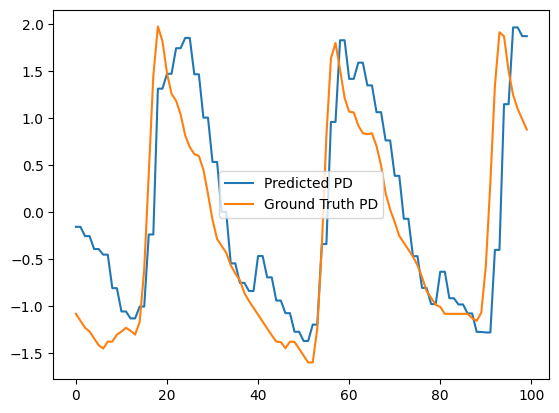

In [10]:
plt.plot(pd_1[:100])
plt.plot(gt_1[:100])
plt.legend(['Predicted PD', 'Ground Truth PD'])

In [12]:
psnr = pearson_corr(pd_1, gt_1)
print(f"Pearson Correlation Coefficient: {psnr}")

TypeError: std() received an invalid combination of arguments - got (ddof=int, dtype=NoneType, out=NoneType, axis=NoneType, ), but expected one of:
 * (tuple of ints dim, bool unbiased, bool keepdim)
 * (tuple of ints dim, *, int correction, bool keepdim)
      didn't match because some of the keywords were incorrect: ddof, dtype, out, axis
 * (bool unbiased)
 * (tuple of names dim, bool unbiased, bool keepdim)
 * (tuple of names dim, *, int correction, bool keepdim)
      didn't match because some of the keywords were incorrect: ddof, dtype, out, axis


In [ ]:
# Update this path to your experiment output
WAVEFORM_PATH = Path('runs/exp/SSMamba_xxx/signal_quality/waveforms.pt')
PRED_KEY = 'pred_norm'  # or 'pred_raw'
DTW_STEP = 2

In [ ]:
def to_1d_numpy(x):
    return x.detach().cpu().numpy().astype(np.float64).reshape(-1)

def reconstruct_subject_signal(subject_chunks):
    keys = sorted(subject_chunks.keys())
    chunks = [to_1d_numpy(subject_chunks[k]) for k in keys]
    return np.concatenate(chunks) if chunks else np.array([], dtype=np.float64)

def pearson_corr(x, y):
    n = min(len(x), len(y))
    if n == 0:
        return np.nan
    x = x[:n]
    y = y[:n]
    if np.std(x) < 1e-12 or np.std(y) < 1e-12:
        return np.nan
    return float(np.corrcoef(x, y)[0, 1])

def dtw_distance(x, y):
    n, m = len(x), len(y)
    if n == 0 or m == 0:
        return np.nan
    dp = np.full((n + 1, m + 1), np.inf, dtype=np.float64)
    dp[0, 0] = 0.0
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = abs(x[i - 1] - y[j - 1])
            dp[i, j] = cost + min(dp[i - 1, j], dp[i, j - 1], dp[i - 1, j - 1])
    return float(dp[n, m])

def projection_snr_db(pred, gt):
    n = min(len(pred), len(gt))
    if n == 0:
        return np.nan
    p, g = pred[:n], gt[:n]
    den = float(np.dot(g, g))
    if den < 1e-12:
        return np.nan
    a = float(np.dot(p, g) / den)
    signal = a * g
    noise = p - signal
    p_sig = float(np.mean(signal ** 2))
    p_noise = float(np.mean(noise ** 2))
    if p_noise < 1e-12:
        return np.inf
    if p_sig < 1e-12:
        return -np.inf
    return float(10.0 * math.log10(p_sig / p_noise))

def compute_psd(x, fs):
    n = len(x)
    if n == 0:
        return np.array([]), np.array([])
    if welch is not None:
        return welch(x, fs=fs, nperseg=min(256, n))
    x = x - np.mean(x)
    fft = np.fft.rfft(x)
    pxx = (np.abs(fft) ** 2) / max(n, 1)
    f = np.fft.rfftfreq(n, d=1.0 / fs)
    return f, pxx

def psd_corr(pred, gt, fs, fmin=0.7, fmax=4.0):
    fp, pp = compute_psd(pred, fs)
    fg, pg = compute_psd(gt, fs)
    if len(fp) == 0 or len(fg) == 0:
        return np.nan
    f = fp if len(fp) <= len(fg) else fg
    pp_i = np.interp(f, fp, pp)
    pg_i = np.interp(f, fg, pg)
    band = (f >= fmin) & (f <= fmax)
    if not np.any(band):
        return np.nan
    a = np.log(pp_i[band] + 1e-12)
    b = np.log(pg_i[band] + 1e-12)
    if np.std(a) < 1e-12 or np.std(b) < 1e-12:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])

In [53]:
data = "/home/muhammadu/SS_Mamba/ss-mamba/runs/SSMamba_20260324_080648/signal_quality/waveforms.pt"
waveforms = torch.load(data)
pd_1 = waveforms['pred_norm']
gt_1 = waveforms['gt']
# pred_norm and gt in waveforms.pt are dicts (subject -> chunk dict), not arrays

m_pearson = []
m_dtw = []
m_snr = []
m_psd_corr = []
m_dtw_2 = []

for subj in sorted(set(pd_1.keys()) & set(gt_1.keys())):
    pred = reconstruct_subject_signal(pd_1[subj])
    gt = reconstruct_subject_signal(gt_1[subj])
    n = min(len(pred), len(gt))
    if n == 0:
        continue
    pred = pred[:n]
    gt = gt[:n]
    print(f"Subject {subj}:")
    print(f"  Pearson Correlation Coefficient: {pearson_corr(pred, gt):.4f}")
    print(f"  DTW Distance: {dtw_distance(pred, gt):.4f}")
    print(f"  Projection SNR (dB): {projection_snr_db(pred, gt):.4f}")
    print(f"  PSD Correlation: {psd_corr(pred, gt, fs=30.0):.4f}")
    print(f"  DTW Distance2: {dtw_w2(pred, gt):.4f}")

    m_pearson.append(pearson_corr(pred, gt))
    m_dtw.append(dtw_distance(pred, gt))
    m_snr.append(projection_snr_db(pred, gt))
    m_psd_corr.append(psd_corr(pred, gt, fs=30.0))
    m_dtw_2.append(dtw_w2(pred, gt))
print('---------Mean Metrics---------')
print(f"Mean Pearson Correlation Coefficient: {np.nanmean(m_pearson):.4f}")
print(f"Mean DTW Distance: {np.nanmean(m_dtw):.4f}")
print(f"Mean Projection SNR (dB): {np.nanmean(m_snr):.4f}")
print(f"Mean PSD Correlation: {np.nanmean(m_psd_corr):.4f}")
print(f"Mean DTW Distance2: {np.nanmean(m_dtw_2):.4f}")


Subject subject41:
  Pearson Correlation Coefficient: 0.7387
  DTW Distance: 572.1241
  Projection SNR (dB): 0.7908
  PSD Correlation: 0.9376
  DTW Distance2: 275.9018
Subject subject42:
  Pearson Correlation Coefficient: 0.8247
  DTW Distance: 528.9534
  Projection SNR (dB): 3.2765
  PSD Correlation: 0.9764
  DTW Distance2: 260.0041
Subject subject43:
  Pearson Correlation Coefficient: 0.7783
  DTW Distance: 512.6066
  Projection SNR (dB): 1.8660
  PSD Correlation: 0.9832
  DTW Distance2: 242.1896
Subject subject44:
  Pearson Correlation Coefficient: 0.8770
  DTW Distance: 380.3124
  Projection SNR (dB): 5.2253
  PSD Correlation: 0.9762
  DTW Distance2: 127.2594
Subject subject45:
  Pearson Correlation Coefficient: 0.8398
  DTW Distance: 565.2104
  Projection SNR (dB): 3.7905
  PSD Correlation: 0.9685
  DTW Distance2: 288.9476
Subject subject46:
  Pearson Correlation Coefficient: 0.8185
  DTW Distance: 443.0281
  Projection SNR (dB): 3.0754
  PSD Correlation: 0.9886
  DTW Distance2: 1

In [ ]:
blob = torch.load(WAVEFORM_PATH, map_location='cpu')
pred_dict = blob[PRED_KEY]
gt_dict = blob['gt']
fs = float(blob.get('fs', 30.0))

rows = []
for subj in sorted(set(pred_dict.keys()) & set(gt_dict.keys())):
    pred = reconstruct_subject_signal(pred_dict[subj])
    gt = reconstruct_subject_signal(gt_dict[subj])
    n = min(len(pred), len(gt))
    if n == 0:
        continue
    pred = pred[:n]
    gt = gt[:n]

    pred_d = pred[::max(DTW_STEP, 1)]
    gt_d = gt[::max(DTW_STEP, 1)]
    dtw = dtw_distance(pred_d, gt_d)

    rows.append({
        'subject': str(subj),
        'num_samples': int(n),
        'pearson': pearson_corr(pred, gt),
        'dtw': dtw,
        'dtw_norm': dtw / max(len(pred_d), len(gt_d), 1) if np.isfinite(dtw) else np.nan,
        'snr_db': projection_snr_db(pred, gt),
        'psd_corr': psd_corr(pred, gt, fs),
    })

df = pd.DataFrame(rows)
df

In [ ]:
summary = df[['pearson', 'dtw', 'dtw_norm', 'snr_db', 'psd_corr']].describe().T
summary

In [ ]:
out_dir = Path('signal')
out_dir.mkdir(exist_ok=True)
df.to_csv(out_dir / 'signal_quality_report.csv', index=False)
summary.to_csv(out_dir / 'signal_quality_summary.csv')
print('Saved:', out_dir / 'signal_quality_report.csv')
print('Saved:', out_dir / 'signal_quality_summary.csv')